# Grip-loss early warning on a UR3 cobot — Step 2: standard solutions

**Machine Learning project – ESILV IRO, 2026–2027** · Quentin Courtois, Mauricio Espinoza, Ivan Devernois

This notebook gathers **all the Step-2 code in one self-contained file**: the shared toolbox (previously the `src/`
package) and the five steps of the project guidelines (previously the scripts `01_…` to `05_…`). Every part follows
the same pattern: **what we do and why** (markdown) → **code** (one figure per cell) → **Reading:** what the result shows, then *Implications:* what we decide from it.

**Problem (from Step 1).** Every second, predict whether a **grip loss will start within the next N = 3 seconds**
from the joint currents, temperatures and speeds and the gripper current of a UR3 cobot (UCI *UR3 CobotOps*,
7,409 rows at ≈ 1 Hz recorded on one day). It is a binary classification on a single multivariate time series,
strongly imbalanced (≈ 3 % positives).

| Part | Content |
|---|---|
| **0. Setup** | imports, configuration, plot style |
| **A. Toolbox** | cleaning, target, causal features, splits, metrics, pipelines, baselines |
| **Step 1** | raw data analysis and pre-processing proposal |
| **Step 2** | learning and testing plan (sets, CV, over/under-fitting, leakage) |
| **Step 3** | baseline solution and its calibration |
| **Step 4** | benchmark models from the state of the art |
| **Step 5** | AutoML pipeline v0.1, evaluation protocol, risks and plan |

**How to run.** Put the notebook in `step2_standard_solutions/` (the data file `UR3CobotOps.csv` is searched in the
notebook folder and in its parent) and use *Run All*. Full run ≈ 25 min on 2 CPU cores, mostly the AutoML search;
set `C.FAST = True` in section 0.2 for a ≈ 10 min run with a smaller search. Figures and tables are also written to
`outputs_notebook/` so that this notebook never overwrites the results of the scripts.

**Two rules applied everywhere.** (1) Every statistic that drives a modelling decision is computed on the
**training period only**. (2) The **test period is used once**, at the very end, after every choice has been made
on training and validation data.

## 0. Setup
### 0.1 Imports
All libraries are standard (`numpy`, `pandas`, `scipy`, `scikit-learn`, `matplotlib`, `joblib`) plus
`imbalanced-learn`, used only in Step 4 to re-run the published SMOTE protocols.

In [1]:
%matplotlib inline
import json
import time
import warnings
from dataclasses import dataclass
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTE
from matplotlib.patches import Patch
from scipy import stats
from scipy.stats import loguniform, randint
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.decomposition import PCA
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score, brier_score_loss,
                             confusion_matrix, f1_score, log_loss, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold, TimeSeriesSplit, cross_val_score,
                                     cross_validate, train_test_split, validation_curve)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline as sk_make_pipeline
from sklearn.preprocessing import RobustScaler, SplineTransformer, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

### 0.2 Configuration
One place for every constant, so that a change (for instance the horizon N) is applied to the whole notebook.

| Constant | Value | Meaning |
|---|---|---|
| `HORIZON` | 3 s | N: an alert at t announces a grip loss starting in (t, t+N] |
| `WINDOW` | 5 s | length of the past window of the rolling features |
| `GAP` | 8 rows | embargo between sets and between CV folds (= N + window) |
| `MERGE_GAP` | 2 rows | two grip-loss episodes separated by ≤ 2 normal rows are one event |
| `FFILL_LIMIT` | 2 s | causal forward fill of empty sensor rows |
| `SPLIT` | 70/15/15 | chronological train / validation / test |
| `MAX_FA_PER_HOUR` | 30 | alert budget of the "trustworthy" operating point |

In [2]:
def _find_csv(name="UR3CobotOps.csv"):
    for folder in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
        if (folder / name).exists():
            return folder / name
    raise FileNotFoundError(f"{name} not found next to the notebook or in its parent folders")


class C:
    """Configuration: paths, column groups and experimental constants."""
    ROOT = Path.cwd()
    DATA_CSV = _find_csv()
    OUT = ROOT / "outputs_notebook"
    FIG, TAB, MODELS = OUT / "figures", OUT / "tables", OUT / "models"

    SEED = 42
    FAST = False            # True -> smaller AutoML search (about 10 min instead of 25)

    CUR = [f"Current_J{i}" for i in range(6)]
    TEM = [f"Temperature_J{i}" for i in range(6)]
    SPD = [f"Speed_J{i}" for i in range(6)]
    TOOL = ["Tool_current"]
    SENSORS = CUR + TEM + SPD + TOOL   # 19 raw sensor channels

    HORIZON = 3
    WINDOW = 5
    GAP = HORIZON + WINDOW
    SEGMENT_BREAK_S = 5.0
    MERGE_GAP = 2
    FFILL_LIMIT = 2
    SPLIT = (0.70, 0.15, 0.15)
    N_SPLITS_CV = 5
    N_BOOT = 1000
    MAX_FA_PER_HOUR = 30.0


for _p in (C.FIG, C.TAB, C.MODELS):
    _p.mkdir(parents=True, exist_ok=True)
print("data file :", C.DATA_CSV)
print("outputs   :", C.OUT)

data file : /home/claude/repo/UR3CobotOps.csv
outputs   : /home/claude/repo/step2_standard_solutions/outputs_notebook


### 0.3 Plot style
One categorical palette used in a fixed order (a colour always means the same thing: blue = train / main model,
orange = validation, aqua = test, red = grip loss), a recessive grid and no dual-axis charts.
`P.save` writes each figure to `outputs_notebook/figures/` and shows it in the notebook.

In [3]:
class P:
    """Plot style shared by all figures."""
    BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
        "#257de0", "#f47230", "#00b894", "#f2a600", "#ee7fac", "#008a17", "#6a4ce2", "#ec4647")
    GRAY, INK, INK2 = "#9c9c9c", "#191919", "#666666"
    SERIES = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED]
    SET_COLORS = {"train": BLUE, "val": ORANGE, "test": AQUA, "embargo": GRAY}
    DIVERGING, SEQUENTIAL = "RdBu_r", "Blues"
    plt = plt

    @staticmethod
    def save(fig, name):
        fig.savefig(C.FIG / name, dpi=160, bbox_inches="tight")
        plt.show()


plt.rcParams.update({
    "figure.dpi": 100, "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold",
    "axes.labelcolor": P.INK, "axes.edgecolor": "#cccccc", "axes.linewidth": 0.8,
    "xtick.color": P.INK2, "ytick.color": P.INK2, "text.color": P.INK,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "lines.linewidth": 2.0,
    "axes.prop_cycle": matplotlib.cycler(color=P.SERIES),
})

## A. Toolbox — functions used by every step
These functions were the `src/` package of the script version. They are defined once here and reused by all steps.
**Design rule:** only the *label* is allowed to look into the future of a row; every feature uses rows ≤ t.

### A.1 Loading and cleaning
* The CSV is in French format (`;` separator, `,` decimal) with a byte-order mark → `encoding="utf-8-sig"`.
* 11 empty trailing columns are dropped, names are stripped (`'cycle '`), `Temperature_T0` is renamed `Temperature_J0`,
  863 quoted timestamps are cleaned, the labels `VRAI/FAUX` become 1/0.
* **The 54 empty rows stay in the time line** (flag `sensor_missing`): deleting them would glue events together and
  shift the lags. 8 of them carry a placeholder `Current_J0 = 1.0`, which is set to NaN.
* **Structure:** a *segment* starts after a time jump > 5 s (4 segments), a *session* after > 1 h (morning / afternoon),
  a *cycle* at each change of the cycle counter (the counter goes back once, 233 → 224, so its values are not unique),
  and `pos` = seconds since the start of the cycle.
* **Label debouncing:** when two grip-loss episodes are separated by only 1–2 normal rows, the hole is treated as label
  flicker and filled (77 → 72 events). Otherwise the rows of the hole would be positives trivially predicted by
  "a loss just happened".

In [4]:
# ----------------------------------------------------------------------------- load
def load_raw(path=C.DATA_CSV) -> pd.DataFrame:
    """Read the CSV exactly as stored (French format: ';' separator, ',' decimal)."""
    return pd.read_csv(path, sep=";", decimal=",", encoding="utf-8-sig")


# ----------------------------------------------------------------------------- clean
def clean(raw: pd.DataFrame, merge_gap: int = C.MERGE_GAP) -> pd.DataFrame:
    """Return one row per recorded second with clean names, types and structure columns.

    All 7,409 rows are kept: the empty rows stay in the timeline (flagged with
    `sensor_missing`) so that durations, lags and events are not distorted.
    """
    df = raw.loc[:, ~raw.columns.str.startswith("Unnamed")].copy()   # 11 empty trailing columns
    df.columns = df.columns.str.strip()                                # 'cycle ' -> 'cycle'
    df = df.rename(columns={"Temperature_T0": "Temperature_J0"})       # T0 is joint J0

    df["ts"] = pd.to_datetime(df["Timestamp"].str.strip('"'), utc=True)  # 863 quoted stamps
    df["GL_raw"] = df["grip_lost"].eq("VRAI").astype(int)
    df["PS"] = df["Robot_ProtectiveStop"].map({"VRAI": 1, "FAUX": 0})   # NaN on empty rows

    # Empty rows: no sensor at all except a placeholder Current_J0 == 1.0 on 8 of them.
    df["sensor_missing"] = df["Current_J1"].isna()
    df.loc[df["sensor_missing"], "Current_J0"] = np.nan

    # Exact duplicates of the measurements (row number and timestamp excluded)
    df["duplicate"] = df.duplicated(subset=C.SENSORS + ["cycle"], keep="first") & ~df["sensor_missing"]

    # ---- time-series structure
    dt = df["ts"].diff().dt.total_seconds()
    df["dt"] = dt
    df["segment"] = (dt > C.SEGMENT_BREAK_S).cumsum()                 # recording breaks
    df["session"] = (dt > 3600).cumsum().map({0: "morning", 1: "afternoon"})
    df["cycle_id"] = (df["cycle"] != df["cycle"].shift()).cumsum()     # counter is not unique
    df["pos"] = df.groupby("cycle_id").cumcount()                      # seconds since cycle start

    # ---- label debouncing: a 1-2 s "hole" inside a grip loss is treated as the same event
    df["GL"] = debounce(df["GL_raw"].to_numpy(), df["segment"].to_numpy(), merge_gap)
    df["onset"] = (df["GL"] == 1) & (df.groupby("segment")["GL"].shift(fill_value=0) == 0)
    df["event_id"] = df["onset"].cumsum().where(df["GL"] == 1)
    return df


def debounce(gl: np.ndarray, segment: np.ndarray, merge_gap: int) -> np.ndarray:
    """Fill runs of <= merge_gap zeros that sit between two ones in the same segment."""
    out = gl.copy()
    if merge_gap <= 0:
        return out
    n = len(gl)
    i = 0
    while i < n:
        if out[i] == 0:
            j = i
            while j < n and out[j] == 0:
                j += 1
            run = j - i
            if 0 < i and j < n and run <= merge_gap and out[i - 1] == 1 and out[j] == 1 \
                    and segment[i - 1] == segment[j]:
                out[i:j] = 1
            i = j
        else:
            i += 1
    return out

### A.2 The early-warning target
$y_t = 1$ if a grip loss **starts** in $(t, t+N]$, i.e. on rows $t+1 \dots t+N$ of the same segment.
A row is **predictable** (used for training and evaluation) only if:
1. no grip loss is ongoing at t (the alert must come *before* the loss — rows during a loss only show its consequences);
2. the sensors were recorded at t;
3. the past window $[t-W+1, t]$ and the future horizon $[t+1, t+N]$ are inside the same segment.

`target_event` remembers which event a positive row announces; it is needed for the event-level metrics.

In [5]:
# ----------------------------------------------------------------------------- target

def make_target(df: pd.DataFrame, horizon: int = C.HORIZON, window: int = C.WINDOW) -> pd.DataFrame:
    """Early-warning label and the mask of rows on which a prediction is made.

    y_t = 1  if a grip loss starts in (t, t+N]   (rows t+1 ... t+N, same segment)
    A row is *predictable* when:
      * no grip loss is ongoing at t (the alert must come before the loss),
      * the sensors were recorded at t,
      * the full past window [t-W+1, t] is in the same segment (features defined),
      * the full future horizon [t+1, t+N] is in the same segment (label defined).
    `target_event` stores which onset a positive row announces (event-level metrics).
    """
    out = df.copy()
    gl = out["GL"].to_numpy()
    seg = out["segment"].to_numpy()
    ev = out["event_id"].to_numpy()
    n = len(out)

    y = np.zeros(n, dtype=int)
    target_event = np.full(n, np.nan)
    target_onset = np.full(n, -1)
    future_ok = np.zeros(n, dtype=bool)
    for t in range(n):
        end = t + horizon
        if end < n and seg[end] == seg[t]:
            future_ok[t] = True
            fut = gl[t + 1:end + 1]
            if fut.any():
                y[t] = 1
                k = t + 1 + int(np.argmax(fut))
                target_event[t] = ev[k]
                target_onset[t] = k

    pos_in_seg = out.groupby("segment").cumcount().to_numpy()
    past_ok = pos_in_seg >= window - 1

    out["y"] = y
    out["target_event"] = target_event
    out["target_onset_ts"] = pd.Series(target_onset, index=out.index).map(
        lambda k: out["ts"].iloc[k] if k >= 0 else pd.NaT)
    out["predictable"] = ((gl == 0) & ~out["sensor_missing"].to_numpy() & ~out["duplicate"].to_numpy()
                          & past_ok & future_ok)
    return out

### A.3 Causal feature engineering
Two levels:
1. `build_base_features` computes, once, every **causal and label-free** candidate feature (or features using labels
   strictly before t): raw sensors after a ≤ 2 s causal forward fill, mean temperature and its 60-s warm-up rate,
   sum of absolute speeds, position in the cycle, and for the 6 currents, the gripper current and `abs_speed`:
   lag 1, lag 2, first difference, 5-s rolling mean and standard deviation (trailing window, never across a break).
   **Burst features**: seconds since the last grip loss and number of onsets in the last 120 s (labels strictly
   before t, reset after the lunch break).
2. `FeatureMaker` is a scikit-learn transformer placed **inside the pipeline**. Everything it *learns* — the normal
   cycle profile used for the residuals (median of each signal at each second of the cycle) and the spline basis
   of the position — is fitted in `fit`, i.e. **on the training fold only**. Its parameters (which blocks to use)
   become hyper-parameters of the AutoML.

| Block | Content |
|---|---|
| `raw` | 6 currents, 6 speeds, gripper current, `abs_speed` |
| `temperature` | `mean` (mean + warm-up rate), `all` (6 raw) or `none` |
| `window` | lags, differences, rolling mean / std |
| `residual` | signal − median at the same position of the cycle (train-fitted) |
| `burst` | time since the last loss, number of recent losses |
| `pos_encoding` | `raw` (trees), `spline` (linear models: non-monotonic effect) or `none` |

In [6]:
DYN = C.CUR + C.TOOL + ["abs_speed"]           # signals that get lag / window features
RESID = C.CUR + C.SPD + C.TOOL + ["abs_speed"]  # signals compared with the normal cycle profile


def build_base_features(df: pd.DataFrame, window: int = C.WINDOW) -> pd.DataFrame:
    seg = df["segment"]
    X = pd.DataFrame(index=df.index)

    # causal forward fill of empty rows (at most FFILL_LIMIT s, never across segments)
    s = df[C.SENSORS].groupby(seg).ffill(limit=C.FFILL_LIMIT)
    X[C.SENSORS] = s
    X["temp_mean"] = s[C.TEM].mean(axis=1)                       # 6 temps: r >= 0.99
    X["abs_speed"] = s[C.SPD].abs().sum(axis=1)
    X["pos"] = df["pos"].astype(float)

    g = X[DYN].groupby(seg)
    for col in DYN:
        gc = g[col]
        X[f"{col}_lag1"] = gc.shift(1)
        X[f"{col}_lag2"] = gc.shift(2)
        X[f"{col}_diff1"] = X[col] - X[f"{col}_lag1"]
        X[f"{col}_rmean{window}"] = gc.transform(lambda v: v.rolling(window, min_periods=window).mean())
        X[f"{col}_rstd{window}"] = gc.transform(lambda v: v.rolling(window, min_periods=window).std())
    X["temp_mean_diff60"] = X["temp_mean"] - X.groupby(seg)["temp_mean"].shift(60)  # warm-up rate

    # burst features: past grip losses only (strictly before t, same session)
    X = X.join(_burst_features(df))
    return X


def _burst_features(df: pd.DataFrame, cap: float = 600.0) -> pd.DataFrame:
    t = (df["ts"] - df["ts"].iloc[0]).dt.total_seconds().to_numpy()
    gl = df["GL"].to_numpy()
    onset = df["onset"].to_numpy()
    sess = df["session"].to_numpy()
    since = np.full(len(df), cap)
    n_recent = np.zeros(len(df))
    last_gl, onsets = None, []
    for i in range(len(df)):
        if i > 0 and sess[i] != sess[i - 1]:
            last_gl, onsets = None, []                 # reset after the 5 h break
        if last_gl is not None:
            since[i] = min(t[i] - last_gl, cap)
        onsets = [o for o in onsets if t[i] - o <= 120]
        n_recent[i] = len(onsets)
        # update AFTER computing row i: row i itself is never used for row i
        if gl[i] == 1:
            last_gl = t[i]
        if onset[i]:
            onsets.append(t[i])
    return pd.DataFrame({"secs_since_last_gl": since, "n_gl_last_120s": n_recent}, index=df.index)

In [6]:
# ----------------------------------------------------------------------------- blocks
def feature_blocks(columns) -> dict[str, list[str]]:
    cols = list(columns)
    return {
        "raw": C.CUR + C.SPD + C.TOOL + ["abs_speed"],
        "temp_all": C.TEM,
        "temp_mean": ["temp_mean", "temp_mean_diff60"],
        "window": [c for c in cols if any(c.endswith(s) for s in
                                          ("_lag1", "_lag2", "_diff1", f"_rmean{C.WINDOW}", f"_rstd{C.WINDOW}"))],
        "burst": ["secs_since_last_gl", "n_gl_last_120s"],
    }


class FeatureMaker(BaseEstimator, TransformerMixin):
    """Select feature blocks and build the train-fitted features.

    Parameters
    ----------
    window   : add lag / diff / rolling features
    residual : add x - median(x | position in cycle), the profile being learned in fit
    burst    : add time since the last grip loss and number of recent losses
    temperature : 'mean' (1 reduced variable + warm-up rate), 'all' (6 raw) or 'none'
    pos_encoding: 'raw' (trees), 'spline' (linear models: non-monotonic effect), 'none'
    """

    def __init__(self, window=True, residual=True, burst=False, temperature="mean",
                 pos_encoding="raw", n_knots=8):
        self.window = window
        self.residual = residual
        self.burst = burst
        self.temperature = temperature
        self.pos_encoding = pos_encoding
        self.n_knots = n_knots

    def fit(self, X: pd.DataFrame, y=None):
        blocks = feature_blocks(X.columns)
        cols = list(blocks["raw"])
        if self.temperature == "mean":
            cols += blocks["temp_mean"]
        elif self.temperature == "all":
            cols += blocks["temp_all"]
        if self.window:
            cols += blocks["window"]
        if self.burst:
            cols += blocks["burst"]
        self.cols_ = cols
        if self.residual:
            pos = X["pos"].clip(upper=self._pos_cap(X))
            self.profile_ = X[RESID].groupby(pos).median()
            self.pos_cap_ = self._pos_cap(X)
        if self.pos_encoding == "spline":
            self.spline_ = SplineTransformer(n_knots=self.n_knots, degree=3, extrapolation="constant")
            self.spline_.fit(X[["pos"]].clip(upper=40))
        self.feature_names_out_ = self._names()
        return self

    @staticmethod
    def _pos_cap(X):
        counts = X["pos"].value_counts()
        ok = counts[counts >= 20].index
        return float(ok.max()) if len(ok) else float(X["pos"].max())

    def _names(self):
        names = list(self.cols_)
        if self.residual:
            names += [f"{c}_res" for c in RESID]
        if self.pos_encoding == "raw":
            names += ["pos"]
        elif self.pos_encoding == "spline":
            names += [f"pos_spline{i}" for i in range(self.spline_.n_features_out_)]
        return names

    def transform(self, X: pd.DataFrame):
        parts = [X[self.cols_].to_numpy(dtype=float)]
        if self.residual:
            pos = X["pos"].clip(upper=self.pos_cap_)
            ref = self.profile_.reindex(pos.to_numpy()).to_numpy()
            parts.append(X[RESID].to_numpy(dtype=float) - ref)
        if self.pos_encoding == "raw":
            parts.append(X[["pos"]].to_numpy(dtype=float))
        elif self.pos_encoding == "spline":
            parts.append(self.spline_.transform(X[["pos"]].clip(upper=40)))
        return np.hstack(parts)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.feature_names_out_, dtype=object)

### A.4 Splits and cross-validation
* **Chronological split** 70/15/15 of the predictable rows; each cut is moved to the next **cycle start** (no cycle in
  two sets) and the 8 rows before each cut form an **embargo** (their label looks into the next set).
* **Cross-validation inside the training period**: expanding window (train on the past, validate on the next block),
  with a gap of 8 rows. The plain `TimeSeriesSplit` cuts equal numbers of *rows*; `event_balanced_cv` places the
  boundaries at *event* quantiles so that every validation fold holds the same number of grip losses (Step 2 shows why).

In [7]:
def chronological_split(df: pd.DataFrame, fractions=C.SPLIT, gap: int = C.GAP) -> pd.Series:
    """Label every row 'train' / 'val' / 'test' / 'embargo' / None (not predictable).

    * cut points are placed at the 70 % and 85 % quantiles of the *predictable* rows,
      then moved forward to the next cycle start, so that no cycle is cut in two;
    * the last `gap` rows before each cut are put in an embargo: their label window
      (t+1 ... t+N) or their past window would otherwise overlap the next set.
    """
    pred_idx = df.index[df["predictable"]]
    cuts = []
    for q in np.cumsum(fractions)[:-1]:
        k = pred_idx[int(round(q * len(pred_idx)))]
        starts = df.index[(df["pos"] == 0) & (df.index >= k)]
        cuts.append(int(starts[0]) if len(starts) else int(k))

    part = pd.Series(None, index=df.index, dtype=object)
    part[df.index < cuts[0]] = "train"
    part[(df.index >= cuts[0]) & (df.index < cuts[1])] = "val"
    part[df.index >= cuts[1]] = "test"
    for c in cuts:
        part[(df.index >= c - gap) & (df.index < c)] = "embargo"
    part[~df["predictable"]] = None
    return part


def ts_cv(n_splits: int = C.N_SPLITS_CV, gap: int = C.GAP) -> TimeSeriesSplit:
    """Expanding-window CV inside the training period, with a gap of `gap` rows."""
    return TimeSeriesSplit(n_splits=n_splits, gap=gap)


def split_summary(df: pd.DataFrame, part: pd.Series) -> pd.DataFrame:
    rows = []
    for name in ["train", "embargo", "val", "test"]:
        d = df[part == name]
        if d.empty:
            continue
        rows.append({
            "set": name,
            "rows": len(d),
            "positives (y=1)": int(d["y"].sum()),
            "prevalence %": round(100 * d["y"].mean(), 2),
            "events announced": int(d["target_event"].nunique()),
            "cycles": int(d["cycle_id"].nunique()),
            "start (UTC)": d["ts"].min().strftime("%H:%M:%S"),
            "end (UTC)": d["ts"].max().strftime("%H:%M:%S"),
            "mean temp J0 (°C)": round(d["Temperature_J0"].mean(), 1),
        })
    return pd.DataFrame(rows)

In [7]:
def event_balanced_cv(target_event: pd.Series, n_splits: int = C.N_SPLITS_CV, gap: int = C.GAP):
    """Expanding-window CV whose validation folds contain the same number of events.

    A plain TimeSeriesSplit cuts the training period into folds of equal *rows*; here one
    fold (around the lunch break) would contain a single grip-loss event, which makes its
    PR-AUC meaningless. The fold boundaries are therefore placed at the event quantiles
    k / (n_splits + 1); training always uses only rows before the fold (minus `gap`).
    Returns a list of (train positions, validation positions), usable as `cv=` in sklearn.
    """
    ev = target_event.to_numpy()
    n = len(ev)
    first_row = {}
    for i, e in enumerate(ev):
        if not np.isnan(e) and e not in first_row:
            first_row[e] = i
    starts = np.sort(np.array(list(first_row.values())))
    n_ev = len(starts)
    bounds = [int(starts[int(np.floor(k * n_ev / (n_splits + 1)))]) for k in range(1, n_splits + 1)]
    # move each boundary back to just after the previous event's announcing rows
    bounds = [max(b - 3, 0) for b in bounds] + [n]
    out = []
    for k in range(n_splits):
        tr = np.arange(0, max(bounds[k] - gap, 0))
        va = np.arange(bounds[k], bounds[k + 1])
        out.append((tr, va))
    return out

### A.5 Metrics
* **Row level**: PR-AUC (average precision — its no-skill value is the prevalence), ROC-AUC, precision, recall, F1,
  balanced accuracy, Brier score.
* **Event level**: an event is *anticipated* if at least one alert is raised in the N seconds before its onset;
  warning time = onset − first alert; a **false-alarm episode** is a run of consecutive alerts on negative rows.
* **Thresholds**: F1-optimal, or the lowest threshold keeping ≤ 30 false alarms per hour (`fa_constrained_threshold`).
* **Uncertainty**: rows are not independent, so confidence intervals resample **whole cycles** (bootstrap); a paired
  version compares two models on the same resampled cycles.

In [8]:
def best_f1_threshold(y, score) -> float:
    """Threshold maximising F1 on the given (validation) data."""
    p, r, t = precision_recall_curve(y, score)
    f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
    i = int(np.nanargmax(f1[:-1])) if len(t) else 0
    return float(t[i]) if len(t) else 0.5


def row_metrics(y, score, thr, proba=True) -> dict:
    y = np.asarray(y)
    score = np.asarray(score)
    pred = (score >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    out = {
        "PR-AUC": average_precision_score(y, score) if y.any() else np.nan,
        "ROC-AUC": roc_auc_score(y, score) if 0 < y.sum() < len(y) else np.nan,
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "balanced acc": balanced_accuracy_score(y, pred),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }
    if proba:
        out["Brier"] = brier_score_loss(y, np.clip(score, 0, 1))
    return out


def event_metrics(ev_df: pd.DataFrame, score, thr) -> dict:
    """ev_df: rows of one evaluation set with 'y', 'target_event', 'ts', 'target_onset_ts'.

    * an event is *detected* if at least one alert is raised in the N seconds before it
      (i.e. on a row whose label announces that event);
    * warning time = onset time - time of the first alert for that event;
    * a false-alarm episode = a run of consecutive alerts on rows with y = 0.
    """
    d = ev_df[["y", "target_event", "ts", "target_onset_ts"]].copy()
    d["alert"] = np.asarray(score) >= thr
    events = d.loc[d["y"] == 1, "target_event"].dropna().unique()
    detected, warn = 0, []
    for e in events:
        rows = d[(d["target_event"] == e)]
        if rows["alert"].any():
            detected += 1
            first = rows.loc[rows["alert"], "ts"].min()
            warn.append((rows["target_onset_ts"].iloc[0] - first).total_seconds())
    fa = (d["alert"] & (d["y"] == 0)).astype(int)
    episodes = int(((fa == 1) & (fa.shift(fill_value=0) == 0)).sum())
    hours = len(d) / 3600.0
    return {
        "events": len(events),
        "events detected": detected,
        "event recall": detected / len(events) if len(events) else np.nan,
        "mean warning (s)": float(np.mean(warn)) if warn else np.nan,
        "false-alarm episodes": episodes,
        "false alarms / hour": episodes / hours if hours else np.nan,
    }

In [8]:
def bootstrap_ci(ev_df: pd.DataFrame, score, fn, groups="cycle_id", n_boot=1000, seed=42,
                 score_b=None):
    """Percentile CI of fn(y, score) by resampling whole cycles (rows are not independent).

    If `score_b` is given, the CI is computed for fn(y, score) - fn(y, score_b)
    on the same resampled cycles (paired comparison).
    """
    rng = np.random.default_rng(seed)
    y = ev_df["y"].to_numpy()
    s = np.asarray(score)
    sb = None if score_b is None else np.asarray(score_b)
    g = ev_df[groups].to_numpy()
    ug = np.unique(g)
    idx_by_g = {k: np.where(g == k)[0] for k in ug}
    vals = []
    for _ in range(n_boot):
        pick = rng.choice(ug, size=len(ug), replace=True)
        idx = np.concatenate([idx_by_g[k] for k in pick])
        if y[idx].sum() == 0:
            continue
        v = fn(y[idx], s[idx])
        if sb is not None:
            v -= fn(y[idx], sb[idx])
        vals.append(v)
    vals = np.asarray(vals)
    point = fn(y, s) - (fn(y, sb) if sb is not None else 0)
    return point, np.percentile(vals, 2.5), np.percentile(vals, 97.5)


def bootstrap_event_recall(ev_df, score, thr, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    d = ev_df.reset_index(drop=True).copy()
    d["_s"] = np.asarray(score)
    cyc = d["cycle_id"].to_numpy()
    ug = np.unique(cyc)
    idx_by_g = {k: np.where(cyc == k)[0] for k in ug}
    vals = []
    for _ in range(n_boot):
        pick = rng.choice(ug, size=len(ug), replace=True)
        parts = []
        for j, k in enumerate(pick):                     # relabel events per draw
            p = d.iloc[idx_by_g[k]].copy()
            p["target_event"] = p["target_event"] + 1e6 * j
            parts.append(p)
        b = pd.concat(parts)
        if b["y"].sum() == 0:
            continue
        vals.append(event_metrics(b, b["_s"], thr)["event recall"])
    point = event_metrics(d, d["_s"], thr)["event recall"]
    return point, np.percentile(vals, 2.5), np.percentile(vals, 97.5)


def fa_constrained_threshold(ev_df: pd.DataFrame, score, max_fa_per_hour: float = 30.0) -> float:
    """Lowest threshold whose false-alarm rate on ev_df stays <= max_fa_per_hour.

    Operating point closer to the business need ("alerts must stay trustworthy") than the
    F1-optimal threshold, which tolerates many short false alarms.
    """
    s = np.asarray(score)
    cands = np.unique(np.quantile(s, np.linspace(0.5, 1.0, 400)))
    for t in cands:                                   # increasing thresholds
        if event_metrics(ev_df, s, t)["false alarms / hour"] <= max_fa_per_hour:
            return float(t)
    return float(s.max() + 1e-9)

### A.6 Pipeline factory and naive baselines
Every model is wrapped in the same pipeline: `FeatureMaker → median imputer → scaler → optional SelectKBest → model`.
Because everything learned from data is inside the pipeline, cross-validation refits it on each training fold.
`PriorBaseline` (B0) and `CyclePositionBaseline` (B1) are the two naive references of Step 3.

In [9]:
def make_pipeline(model, scaler="standard", k_best=None, **fm_kwargs) -> Pipeline:
    steps = [
        ("features", FeatureMaker(**fm_kwargs)),
        ("impute", SimpleImputer(strategy="median")),
        ("scale", {"standard": StandardScaler(), "robust": RobustScaler(), None: "passthrough"}[scaler]),
        ("select", SelectKBest(f_classif, k=k_best) if k_best else "passthrough"),
        ("model", model),
    ]
    return Pipeline(steps)


def scores(pipe, X):
    """Continuous score used for ranking (probability if available)."""
    if hasattr(pipe, "predict_proba"):
        try:
            return pipe.predict_proba(X)[:, 1]
        except AttributeError:
            pass
    return pipe.decision_function(X)


class PriorBaseline(BaseEstimator, ClassifierMixin):
    def fit(self, X, y):
        self.p_ = float(np.mean(y)); self.classes_ = np.array([0, 1]); return self

    def predict_proba(self, X):
        return np.c_[np.full(len(X), 1 - self.p_), np.full(len(X), self.p_)]


class CyclePositionBaseline(BaseEstimator, ClassifierMixin):
    """P(y = 1 | position in cycle), Laplace-smoothed toward the prior (alpha pseudo-rows)."""

    def __init__(self, alpha=20.0, cap=40):
        self.alpha, self.cap = alpha, cap

    def fit(self, X, y):
        pos = X["pos"].clip(upper=self.cap).astype(int)
        y = np.asarray(y)
        self.prior_ = y.mean()
        g = pd.DataFrame({"pos": pos.to_numpy(), "y": y}).groupby("pos")["y"].agg(["sum", "count"])
        self.rate_ = (g["sum"] + self.alpha * self.prior_) / (g["count"] + self.alpha)
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        p = X["pos"].clip(upper=self.cap).astype(int).map(self.rate_).fillna(self.prior_).to_numpy()
        return np.c_[1 - p, p]

### A.7 Prepare the data once
`prepare()` chains cleaning → target → causal features → split. The result `D` is reused by all steps;
`D.get("train")` returns the features, the labels and the full rows of a set.

In [10]:
@dataclass
class Prepared:
    df: pd.DataFrame          # full time line with labels and structure columns
    X: pd.DataFrame           # causal candidate features (whole time line)
    part: pd.Series           # 'train' / 'val' / 'test' / 'embargo' / None

    def get(self, name):
        m = self.part == name
        return self.X.loc[m], self.df.loc[m, "y"], self.df.loc[m]


def prepare(horizon: int = C.HORIZON, window: int = C.WINDOW) -> Prepared:
    df = make_target(clean(load_raw()), horizon=horizon, window=window)
    X = build_base_features(df, window=window)
    part = chronological_split(df, gap=horizon + window)
    return Prepared(df, X, part)


D = prepare()
print("rows:", len(D.df), "| predictable:", int(D.df["predictable"].sum()),
      "| positives:", int(D.df.loc[D.df["predictable"], "y"].sum()),
      "| events:", int(D.df["onset"].sum()), "| candidate features:", D.X.shape[1])
D.part.value_counts()

rows: 7409 | predictable: 7082 | positives: 209 | events: 72 | candidate features: 65


train      4961
val        1061
test       1046
embargo      14
Name: count, dtype: int64

## Step 1 — Raw data analysis and pre-processing proposal
Quality checks, statistics, variable definitions, class imbalance, missing data, correlation and reduction,
non-stationarity, information carried by each signal, and the resulting pre-processing.
The first cell rebuilds the objects used in this step; `train_period` marks the whole time line before the
validation period, on which every decision-driving statistic is computed.

In [11]:
raw = load_raw()
df = make_target(clean(raw))
X = build_base_features(df)
part = chronological_split(df)
train_period = df.index < df.index[part == "val"].min()   # whole timeline before validation

### 1.1 Data-quality report
Each check is computed from the file, not copied from our Step-1 document.

In [12]:
empty_cols = [c for c in raw.columns if c.startswith("Unnamed")]
space_cols = [c for c in raw.columns if c != c.strip()]
dt = df["dt"]
cyc = df["cycle"].to_numpy()
decreases = np.where(np.diff(cyc) < 0)[0]
dup_all = raw.drop(columns=["Num", "Timestamp"] + empty_cols).duplicated(keep=False)
placeholder = raw["Current_J0"].eq(1.0) & raw["Current_J1"].isna()
breaks = dt[dt > C.SEGMENT_BREAK_S]

quality = pd.DataFrame([
    ("Rows / columns in the file", f"{len(raw)} rows, {raw.shape[1]} columns ({len(empty_cols)} completely empty)", "Drop the empty columns"),
    ("Column names", f"{len(space_cols)} name(s) with a trailing space: {space_cols}; 'Temperature_T0' is joint J0", "Strip names, rename T0 -> J0"),
    ("Labels stored as text", "grip_lost / Robot_ProtectiveStop are 'VRAI'/'FAUX' strings", "Map to 0/1"),
    ("Timestamps", f"{raw['Timestamp'].str.startswith(chr(34)).sum()} timestamps wrapped in quotes", "Strip quotes, parse as UTC"),
    ("Empty sensor rows", f"{df['sensor_missing'].sum()} rows without sensor values ({placeholder.sum()} carry a placeholder Current_J0 = 1.0); "
                         f"PS label missing on the same rows; grip_lost = 0 on all of them", "Keep in the time line, never predict on them, causal ffill (<= 2 s) for windows"),
    ("Duplicated rows", f"{dup_all.sum()} rows involved, all of them empty rows sharing a cycle number; 0 duplicated measurements", "Nothing to remove"),
    ("Sampling", f"median interval {dt.median():.3f} s; {int(((dt > 1.5) & (dt <= 2.5)).sum())} intervals of ~2 s (one record skipped)", "Lags are counted in rows (~ seconds)"),
    ("Recording breaks", ", ".join(f"{b:.0f} s" for b in breaks) + f" -> {df['segment'].nunique()} continuous segments", "No lag / window / label across a break"),
    ("Cycle counter", f"decreases {len(decreases)} time(s): {cyc[decreases[0]]} -> {cyc[decreases[0] + 1]} between Num {raw['Num'].iat[decreases[0]]} and Num {raw['Num'].iat[decreases[0] + 1]}" if len(decreases) else "monotonic",
     "Cycles identified by changes of the counter"),
    ("Grip-loss label", f"{int(df['GL_raw'].sum())} rows, {int(((df['GL_raw'] == 1) & (df['GL_raw'].shift(fill_value=0) == 0)).sum())} raw events; "
                        f"5 pairs separated by only 1-2 normal rows", f"Debounce: merge gaps <= {C.MERGE_GAP} rows -> {int(df['onset'].sum())} events"),
], columns=["check", "finding", "action"])
quality.to_csv(C.TAB / "s1_quality_report.csv", index=False)
print(quality.to_string())

                        check                                                                                                                                  finding                                                                           action
0  Rows / columns in the file                                                                                              7409 rows, 35 columns (11 completely empty)                                                           Drop the empty columns
1                Column names                                                                1 name(s) with a trailing space: ['cycle ']; 'Temperature_T0' is joint J0                                                     Strip names, rename T0 -> J0
2       Labels stored as text                                                                               grip_lost / Robot_ProtectiveStop are 'VRAI'/'FAUX' strings                                                                       Map to 0/1
3       

**Reading:**
- two statements of our Step-1 document are corrected: the "2 duplicated rows" are **empty rows that share a cycle number** (no duplicated measurement), and the cycle counter goes **233 → 224** (not 232 → 224);
- 8 empty rows carry a placeholder `Current_J0 = 1.0`, which our exploratory notebook counted as real data;
- the 24 intervals of ~2 s are skipped records inside a segment; there are 3 real recording breaks (9 s, 31 s and the 5 h 13 min lunch break).

*Implications:* nothing has to be removed; the placeholders are set to NaN, lags are counted in rows (≈ seconds), and no window, lag or label may cross a recording break.

### 1.2 Variable dictionary
Type, unit and role of every column. The target is built from `grip_lost`; `Robot_ProtectiveStop` is another fault,
unrelated to grip losses (Step 1: Fisher p = 0.25), and is excluded.

In [13]:
var_dict = pd.DataFrame(
    [("Num", "integer", "-", "identifier", "row number, dropped")]
    + [("Timestamp", "datetime (UTC)", "-", "index", "used for ordering, breaks and splits only")]
    + [(c, "continuous", "A", "feature", "joint motor current") for c in C.CUR]
    + [(c, "continuous", "°C", "feature (reduced)", "joint temperature, the 6 are replaced by their mean") for c in C.TEM]
    + [(c, "continuous", "rad/s", "feature", "joint speed") for c in C.SPD]
    + [("Tool_current", "continuous", "A", "feature", "gripper current")]
    + [("cycle", "integer", "-", "structure", "cycle counter -> cycle_id and position in cycle; not a feature (encodes time)")]
    + [("Robot_ProtectiveStop", "binary", "-", "excluded", "other fault, unrelated to grip loss (Fisher p = 0.25)")]
    + [("grip_lost", "binary", "-", "target source", f"y_t = 1 if a grip loss starts within the next N = {C.HORIZON} s")],
    columns=["variable", "type", "unit", "role", "comment"])
var_dict.to_csv(C.TAB / "s1_variable_dictionary.csv", index=False)
var_dict

,variable,type,unit,role,comment
0,Num,integer,-,identifier,"row number, dropped"
1,Timestamp,datetime (UTC),-,index,"used for ordering, breaks and splits only"
2,Current_J0,continuous,A,feature,joint motor current
3,Current_J1,continuous,A,feature,joint motor current
4,Current_J2,continuous,A,feature,joint motor current
5,Current_J3,continuous,A,feature,joint motor current
6,Current_J4,continuous,A,feature,joint motor current
7,Current_J5,continuous,A,feature,joint motor current
8,Temperature_J0,continuous,°C,feature (reduced),"joint temperature, the 6 are replaced by their mean"
9,Temperature_J1,continuous,°C,feature (reduced),"joint temperature, the 6 are replaced by their mean"


### 1.3 Descriptive statistics, normality, autocorrelation, outliers
`normaltest` = D'Agostino–Pearson test; *effective n* = n(1−ρ)/(1+ρ) with ρ the lag-1 autocorrelation. For outliers the
usual IQR rule is useless on the speeds (the robot is stopped half of the time, IQR ≈ 0): we report the share of values
beyond 5 standard deviations and the share of ≈ 0 values.

In [14]:
d = df.loc[~df["sensor_missing"]]
desc = d[C.SENSORS].describe().T
desc["skew"] = d[C.SENSORS].skew()
desc["kurtosis"] = d[C.SENSORS].kurt()
desc["normaltest p"] = [stats.normaltest(d[c]).pvalue for c in C.SENSORS]
desc["lag-1 autocorr"] = [d[c].autocorr(1) for c in C.SENSORS]
rho = desc["lag-1 autocorr"].clip(-0.99, 0.99)
desc["effective n"] = (len(d) * (1 - rho) / (1 + rho)).round(0)
# outliers: the IQR rule is meaningless for the speeds (the robot is stopped ~50 % of the
# time, so IQR ~ 0); we report |x - mean| > 5 sd and the share of ~zero values instead
desc["beyond 5 sd %"] = (((d[C.SENSORS] - d[C.SENSORS].mean()).abs() > 5 * d[C.SENSORS].std()).mean() * 100).round(2)
desc["~zero values %"] = ((d[C.SENSORS].abs() < 1e-3).mean() * 100).round(1)
desc = desc.round(4)
desc.to_csv(C.TAB / "s1_descriptive_stats.csv")
print(desc[["mean", "std", "min", "max", "skew", "kurtosis", "lag-1 autocorr", "beyond 5 sd %", "~zero values %"]].to_string())

                   mean     std      min      max    skew  kurtosis  lag-1 autocorr  beyond 5 sd %  ~zero values %
Current_J0      -0.0501  0.8291  -6.2478   6.8069  0.0359   23.0494         -0.0223           1.43             0.3
Current_J1      -2.2979  0.8004  -5.8087   1.0836 -0.5293    2.8641          0.2717           0.00             0.0
Current_J2      -1.1994  0.6100  -4.1720   2.4649 -0.1119    4.5467          0.1828           0.15             0.0
Current_J3      -0.6053  0.5149  -3.3331   2.2703  0.3803    4.7339          0.0479           0.07             0.0
Current_J4      -0.0230  0.6308  -4.7384   4.0894  0.1259   14.5733         -0.0105           0.92             0.8
Current_J5       0.0009  0.1291  -0.4746   0.3925 -0.1300   -0.2668          0.2968           0.00             0.7
Temperature_J0  34.9068  2.7621  27.8125  37.2500 -1.0069   -0.3179          0.9999           0.00             0.0
Temperature_J1  37.6596  3.2473  29.3125  40.5000 -1.0127   -0.3232          0.9

**Reading:**
- **no sensor is Gaussian** (p ≈ 0 for all): currents J0 and J4 have very heavy tails (kurtosis 23 and 15) and the gripper current is right-skewed (3.9);
- **speeds are ≈ 0 about half of the time** (46–61 %); at most 1.4 % of the values are beyond 5 sd and all are physically plausible (|speed| ≤ 2.73 rad/s < 3.14 rad/s, the 180°/s limit of the UR3 base joints);
- **temperatures change extremely slowly** (lag-1 autocorrelation 0.9999); currents are weakly autocorrelated at 1 Hz.

*Implications:* rank-based statistics, median imputation and Standard *or* Robust scaling (an AutoML choice). **No outlier removal**: the extreme currents are the start/stop dynamics we want to learn. Rows are not independent samples: cycles and events are the real units, hence the cycle bootstrap for every confidence interval.

### 1.4 Class imbalance
Imbalance of the raw label and of the early-warning target for several horizons N.

   horizon N (s)  predictable rows  positives  prevalence % imbalance ratio  events announced
0              1              7090         69          0.97           1:102                69
1              2              7086        140          1.98            1:50                71
2              3              7082        209          2.95            1:33                71
3              4              7078        279          3.94            1:24                71
4              5              7074        347          4.91            1:19                71


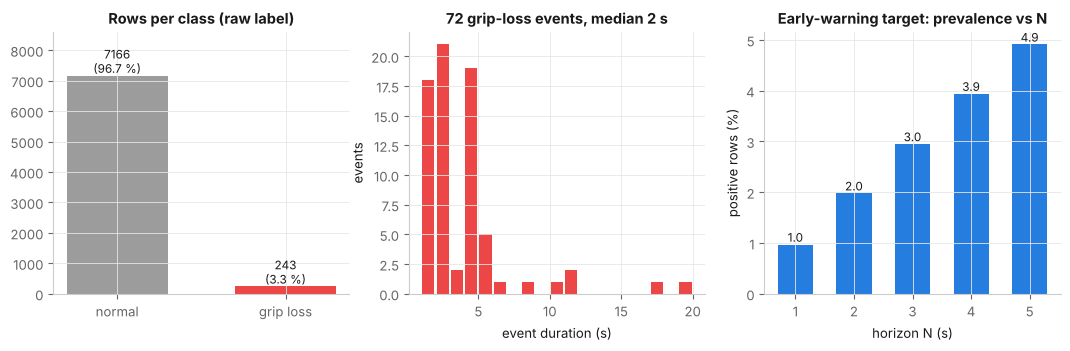

In [15]:
ev = df[df["GL"] == 1].groupby("event_id").size()
imb_rows = []
for N in [1, 2, 3, 4, 5]:
    t = make_target(df, horizon=N)
    pr = t[t["predictable"]]
    imb_rows.append({"horizon N (s)": N, "predictable rows": len(pr), "positives": int(pr["y"].sum()),
                     "prevalence %": round(100 * pr["y"].mean(), 2),
                     "imbalance ratio": f"1:{(1 - pr['y'].mean()) / pr['y'].mean():.0f}",
                     "events announced": pr["target_event"].nunique()})
imbalance = pd.DataFrame(imb_rows)
imbalance.to_csv(C.TAB / "s1_imbalance_by_horizon.csv", index=False)
print(imbalance.to_string())

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
counts = [int((df["GL_raw"] == 0).sum()), int(df["GL_raw"].sum())]
ax[0].bar(["normal", "grip loss"], counts, color=[P.GRAY, P.RED], width=.6)
for i, v in enumerate(counts):
    ax[0].text(i, v, f"{v}\n({100 * v / sum(counts):.1f} %)", ha="center", va="bottom", fontsize=8.5)
ax[0].set_title("Rows per class (raw label)"); ax[0].set_ylim(0, counts[0] * 1.2)
ax[1].hist(ev.values, bins=range(1, ev.max() + 2), color=P.RED, rwidth=.85)
ax[1].set_xlabel("event duration (s)"); ax[1].set_ylabel("events")
ax[1].set_title(f"{len(ev)} grip-loss events, median {ev.median():.0f} s")
ax[2].bar(imbalance["horizon N (s)"], imbalance["prevalence %"], color=P.BLUE, width=.6)
for x_, v in zip(imbalance["horizon N (s)"], imbalance["prevalence %"]):
    ax[2].text(x_, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8.5)
ax[2].set_xlabel("horizon N (s)"); ax[2].set_ylabel("positive rows (%)")
ax[2].set_title("Early-warning target: prevalence vs N")
P.save(fig, "s1_fig02_imbalance.png")

**Reading:**
- *left*: 3.3 % of the rows are grip-loss rows (raw label);
- *middle*: after debouncing, 72 events with a median duration of 2 s (39 of them last 1–2 s, 19 last 4 s);
- *right*: with N = 3 s, 209 of 7,082 predictable rows are positive (**2.95 %, ratio 1:33**); the prevalence grows with N, from 0.97 % (N = 1) to 4.91 % (N = 5).

*Implications:* always predicting "no loss" would give 97 % accuracy, so **accuracy is not used**: the main metrics are PR-AUC and event recall at a fixed false-alarm budget. Imbalance is handled with **class weights** inside the training folds; SMOTE interpolates between consecutive, non-independent seconds and is only used in Step 4 to reproduce the literature.

### 1.5 Missing rows: where are they, and are they random?
Fisher exact tests: empty rows vs session, and empty rows vs "within 10 s before an onset".

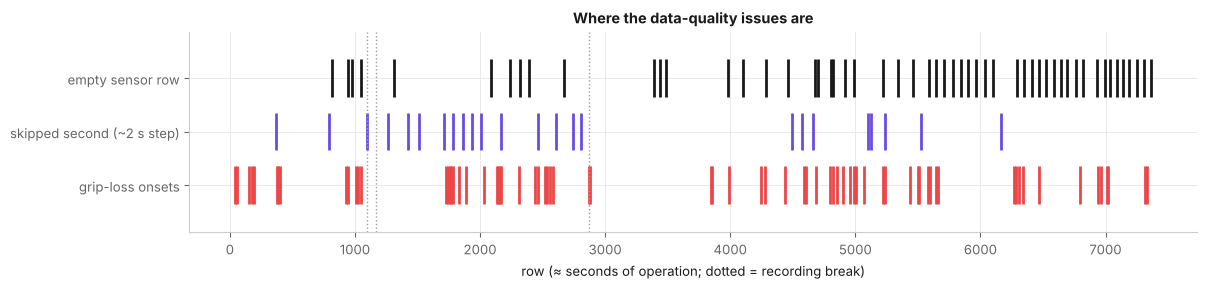

                                             test                     table   p-value
0                  empty rows vs session (Fisher)  [[4496, 2859], [44, 10]]  0.001838
1  empty rows vs <= 10 s before an onset (Fisher)    [[6644, 711], [47, 7]]  0.359767


In [16]:
fig, ax = plt.subplots(figsize=(13, 2.6))
idx = np.arange(len(df))
ax.eventplot([idx[df["sensor_missing"]]], lineoffsets=2, colors=P.INK, linelengths=.7)
ax.eventplot([idx[(dt > 1.5) & (dt <= 2.5)]], lineoffsets=1, colors=P.VIOLET, linelengths=.7)
ax.eventplot([idx[df["onset"]]], lineoffsets=0, colors=P.RED, linelengths=.7)
for b in idx[df["segment"].diff() > 0]:
    ax.axvline(b, color=P.GRAY, ls=":", lw=1)
ax.set_yticks([0, 1, 2], ["grip-loss onsets", "skipped second (~2 s step)", "empty sensor row"])
ax.set_xlabel("row (≈ seconds of operation; dotted = recording break)")
ax.set_title("Where the data-quality issues are")
P.save(fig, "s1_fig01_missing_timeline.png")

near = np.zeros(len(df), bool)                                  # within 10 s before an onset
for o in idx[df["onset"]]:
    near[max(0, o - 10):o] = True
tab = pd.crosstab(df["sensor_missing"], near)
miss_tests = pd.DataFrame([
    {"test": "empty rows vs session (Fisher)", "table": pd.crosstab(df["sensor_missing"], df["session"]).values.tolist(),
     "p-value": stats.fisher_exact(pd.crosstab(df["sensor_missing"], df["session"]).values)[1]},
    {"test": "empty rows vs <= 10 s before an onset (Fisher)", "table": tab.values.tolist(),
     "p-value": stats.fisher_exact(tab.values)[1]},
])
miss_tests.to_csv(C.TAB / "s1_missingness_tests.csv", index=False)
print(miss_tests.to_string())

**Reading:**
- empty rows are more frequent in the **afternoon** (44 of 4,540 rows vs 10 of 2,869 in the morning, Fisher p = 0.002): they are not missing completely at random with respect to time;
- they are **not** linked to grip losses: 7 of 54 are within 10 s before an onset (p = 0.36), and none is a grip-loss row.

*Implications:* keep them as "no measurement" seconds in the time line, never predict on them, and forward-fill causally for at most 2 s so that the windows of neighbouring rows stay defined.

### 1.6 Correlation, multicollinearity (VIF) and dimensionality reduction — training period
Spearman correlations (robust to the heavy tails), variance inflation factors before / after replacing the six
temperatures by their mean, PCA on the temperatures and on all standardised sensors.

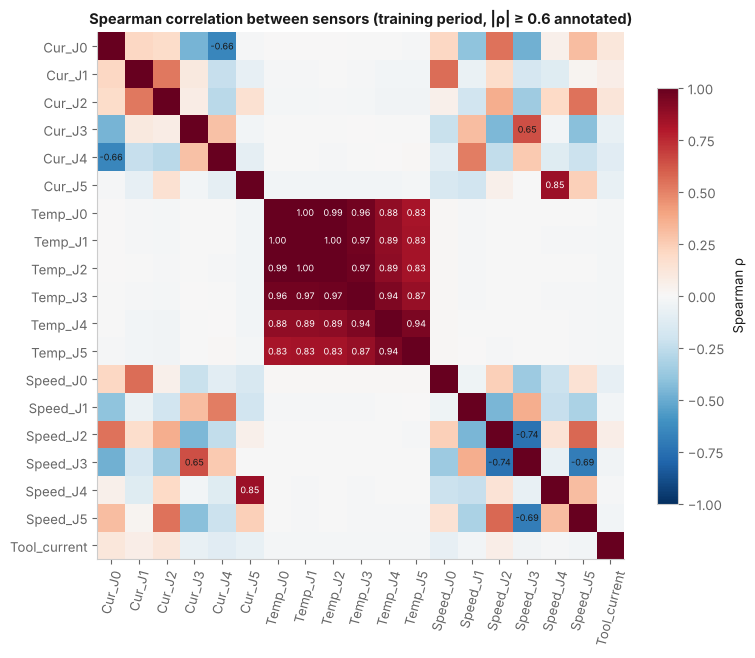

In [17]:
dtr = df.loc[train_period & ~df["sensor_missing"]]
spear = dtr[C.SENSORS].corr("spearman")
pear = dtr[C.SENSORS].corr("pearson")
fig, ax = plt.subplots(figsize=(8.5, 7.2))
im = ax.imshow(spear, cmap=P.DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(C.SENSORS)), [s.replace("Temperature", "Temp").replace("Current", "Cur") for s in C.SENSORS], rotation=75)
ax.set_yticks(range(len(C.SENSORS)), [s.replace("Temperature", "Temp").replace("Current", "Cur") for s in C.SENSORS])
ax.grid(False)
for i in range(len(C.SENSORS)):
    for j in range(len(C.SENSORS)):
        if abs(spear.iat[i, j]) >= .6 and i != j:
            ax.text(j, i, f"{spear.iat[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                    color="white" if abs(spear.iat[i, j]) > .8 else P.INK)
fig.colorbar(im, ax=ax, shrink=.75, label="Spearman ρ")
ax.set_title("Spearman correlation between sensors (training period, |ρ| ≥ 0.6 annotated)")
P.save(fig, "s1_fig03_correlation.png")

**Reading:**
- the **six temperatures form one dark block** (ρ close to 1): they all measure the global warm-up of the robot;
- the speeds are kinematically coupled (Speed_J2 / Speed_J3 ρ = −0.74, Speed_J3 / Speed_J5 ρ = −0.69), and Current_J5 follows Speed_J4 (ρ = 0.85).

*Implications:* the temperatures can be reduced to a single variable. The other couplings are partial (|ρ| < 0.9), so these signals carry different information and are kept.

                             analysis                                result
0           PCA on the 6 temperatures  PC1 explains 99.85 % of the variance
1  PCA on the 19 standardised sensors     7 components for 90 %, 9 for 95 %
2            Max VIF before reduction                 8988 (Temperature_J2)
3  Max VIF after temperatures -> mean                      165.3 (Speed_J3)


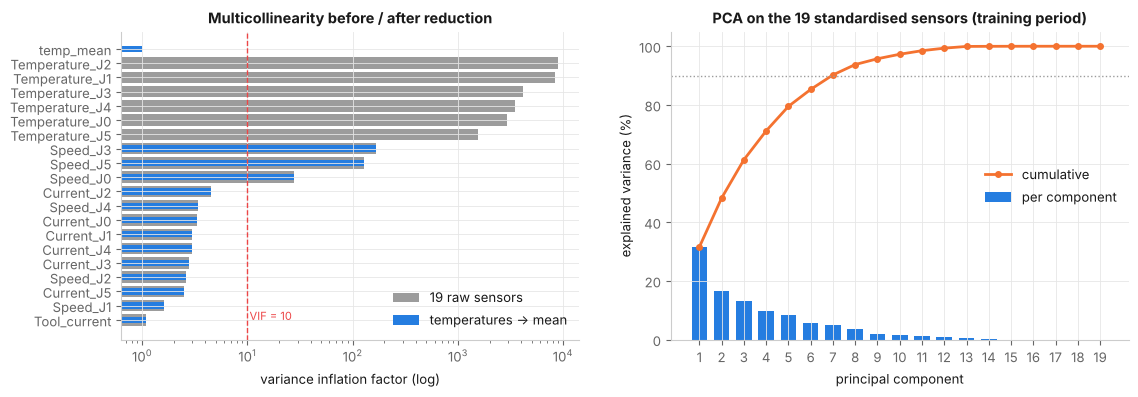

In [17]:
pairs = []
for i, a in enumerate(C.SENSORS):
    for b in C.SENSORS[i + 1:]:
        pairs.append((a, b, pear.loc[a, b], spear.loc[a, b]))
pairs = pd.DataFrame(pairs, columns=["var 1", "var 2", "pearson", "spearman"])
pairs = pairs.reindex(pairs["spearman"].abs().sort_values(ascending=False).index)
pairs.head(25).round(3).to_csv(C.TAB / "s1_top_correlated_pairs.csv", index=False)


def vif(frame: pd.DataFrame) -> pd.Series:
    Z = StandardScaler().fit_transform(frame)
    out = {}
    for k, col in enumerate(frame.columns):
        others = np.delete(Z, k, axis=1)
        beta, *_ = np.linalg.lstsq(np.c_[np.ones(len(Z)), others], Z[:, k], rcond=None)
        resid = Z[:, k] - np.c_[np.ones(len(Z)), others] @ beta
        r2 = 1 - resid.var() / Z[:, k].var()
        out[col] = 1 / max(1 - r2, 1e-9)
    return pd.Series(out)


vif_before = vif(dtr[C.SENSORS])
reduced = dtr[C.CUR + C.SPD + C.TOOL].assign(temp_mean=dtr[C.TEM].mean(axis=1))
vif_after = vif(reduced)
vif_tab = pd.DataFrame({"VIF (19 raw sensors)": vif_before, "VIF (temperatures -> mean)": vif_after}).round(1)
vif_tab.to_csv(C.TAB / "s1_vif.csv")

pca_t = PCA().fit(StandardScaler().fit_transform(dtr[C.TEM]))
pca_all = PCA().fit(StandardScaler().fit_transform(dtr[C.SENSORS]))
cum = np.cumsum(pca_all.explained_variance_ratio_)
reduction = pd.DataFrame([
    {"analysis": "PCA on the 6 temperatures", "result": f"PC1 explains {100 * pca_t.explained_variance_ratio_[0]:.2f} % of the variance"},
    {"analysis": "PCA on the 19 standardised sensors", "result": f"{np.searchsorted(cum, .90) + 1} components for 90 %, {np.searchsorted(cum, .95) + 1} for 95 %"},
    {"analysis": "Max VIF before reduction", "result": f"{vif_before.max():.0f} ({vif_before.idxmax()})"},
    {"analysis": "Max VIF after temperatures -> mean", "result": f"{vif_after.max():.1f} ({vif_after.idxmax()})"},
])
reduction.to_csv(C.TAB / "s1_reduction.csv", index=False)
print(reduction.to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
vv = vif_tab.sort_values("VIF (19 raw sensors)")
ax[0].barh(vv.index, vv["VIF (19 raw sensors)"], color=P.GRAY, label="19 raw sensors")
ax[0].barh(vv.index, vv["VIF (temperatures -> mean)"].fillna(0), color=P.BLUE, height=.45, label="temperatures -> mean")
ax[0].set_xscale("log"); ax[0].axvline(10, color=P.RED, ls="--", lw=1)
ax[0].text(10.5, 0, "VIF = 10", color=P.RED, fontsize=8)
ax[0].set_xlabel("variance inflation factor (log)"); ax[0].legend(loc="lower right")
ax[0].set_title("Multicollinearity before / after reduction")
ax[1].bar(range(1, 20), 100 * pca_all.explained_variance_ratio_, color=P.BLUE, width=.7, label="per component")
ax[1].plot(range(1, 20), 100 * cum, color=P.ORANGE, marker="o", ms=4, label="cumulative")
ax[1].axhline(90, color=P.GRAY, ls=":", lw=1)
ax[1].set_xlabel("principal component"); ax[1].set_ylabel("explained variance (%)")
ax[1].set_xticks(range(1, 20)); ax[1].legend(loc="center right")
ax[1].set_title("PCA on the 19 standardised sensors (training period)")
P.save(fig, "s1_fig04_vif_pca.png")

**Reading:**
- *left*: the temperatures have VIFs up to ≈ 9,000 (PC1 = 99.85 % of their variance); after replacing them by their mean, the highest VIF is still 165 (Speed_J3), because of the speed couplings;
- *right*: a global PCA needs 7 components for 90 % of the variance (9 for 95 %).

*Implications:* the six temperatures are replaced by their **mean + a 60-s warm-up rate**. All speeds are kept (different joints of the trajectory); L1/L2 penalties and the optional SelectKBest handle the remaining collinearity, and trees ignore it. PCA is **not** used: the variance it keeps is not the one that predicts grip losses (section 1.8), and the features would lose their physical meaning.

### 1.7 Non-stationarity and confounding
Grip-loss rate and mean temperature per block of 500 rows (two panels, one axis each).

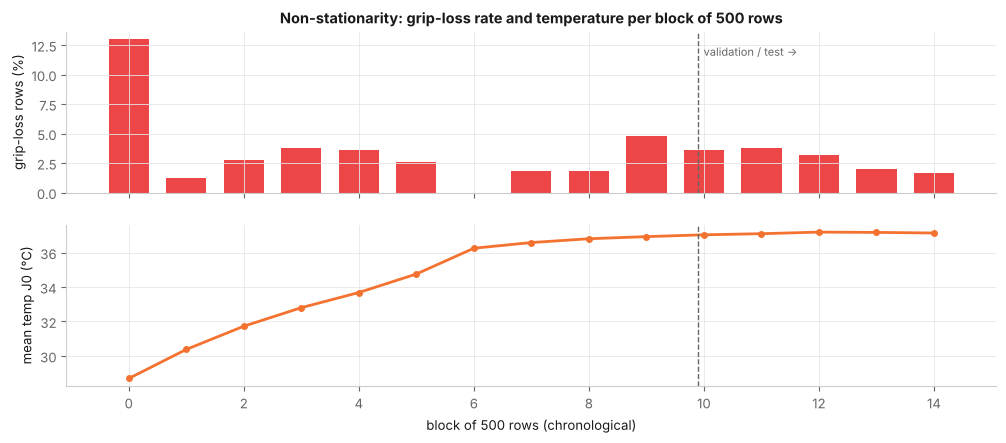

In [18]:
blk = d.groupby(np.arange(len(d)) // 500).agg(rate=("GL", "mean"), temp=("Temperature_J0", "mean"))
fig, ax = plt.subplots(2, 1, figsize=(12, 4.6), sharex=True)
ax[0].bar(blk.index, 100 * blk["rate"], color=P.RED, width=.7)
ax[0].set_ylabel("grip-loss rows (%)"); ax[0].set_title("Non-stationarity: grip-loss rate and temperature per block of 500 rows")
ax[1].plot(blk.index, blk["temp"], color=P.ORANGE, marker="o", ms=4)
ax[1].set_ylabel("mean temp J0 (°C)"); ax[1].set_xlabel("block of 500 rows (chronological)")
cut_blk = (df.index[part == "val"].min()) / 500
for a in ax:
    a.axvline(cut_blk - .5, color=P.INK2, ls="--", lw=1)
ax[0].text(cut_blk - .4, ax[0].get_ylim()[1] * .85, "validation / test →", fontsize=8, color=P.INK2)
P.save(fig, "s1_fig06_drift.png")

**Reading:**
- grip losses are **4× more frequent in the first 500 rows** (cold robot), then stay around 2–4 %;
- the temperature rises during the morning and stays warm in the validation and test periods (right of the dashed line).

*Implications:* temperature and "start of the day" are **confounded**: a model using the temperature would mostly learn "early morning", which never happens in the warm validation and test periods. Temperature is therefore a block that the AutoML may switch off, and its effect is checked by ablation in Step 5.

### 1.8 Which signals carry information **before** the loss? (training period)
Univariate ROC-AUC of each candidate feature for the concurrent label (during the loss, gray) and for our early-warning
label (blue), mutual information, and a 95 % cycle-bootstrap interval for the 10 strongest features.

               feature  AUC concurrent (during loss)  AUC early warning (N=3)  |AUC-0.5| early  mutual info (early) 95% CI early AUC (cycle bootstrap)
0    Current_J1_rmean5                         0.755                    0.724            0.224                0.011                       [0.67, 0.78]
1   secs_since_last_gl                         0.099                    0.312            0.188                0.012                       [0.24, 0.39]
2      Current_J1_lag2                         0.640                    0.687            0.187                0.011                       [0.65, 0.73]
3     Current_J1_rstd5                         0.347                    0.338            0.162                0.011                       [0.29, 0.39]
4           Current_J1                         0.646                    0.643            0.143                0.008                       [0.61, 0.68]
5      Current_J1_lag1                         0.639                    0.638            0.138

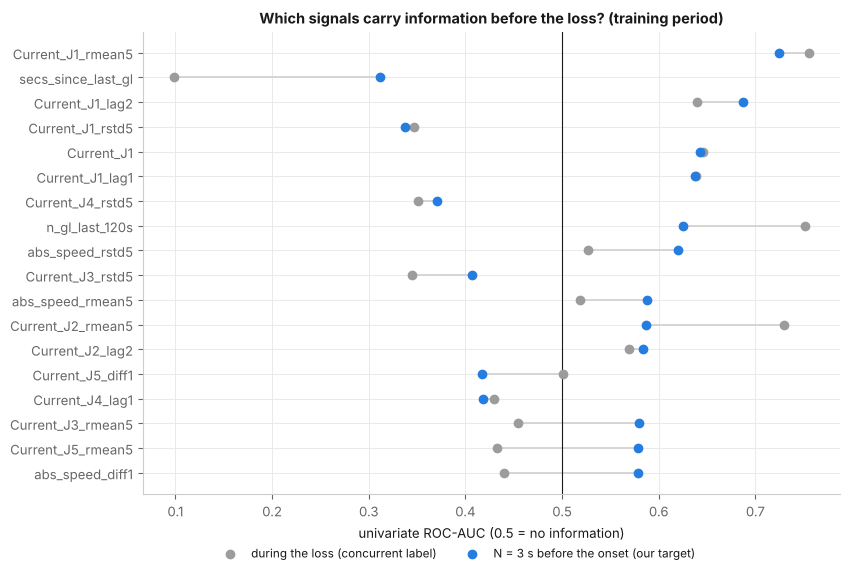

In [19]:
cand = [c for c in X.columns if c not in ("pos",)] + ["pos"]
conc_mask = train_period & ~df["sensor_missing"]
pred_mask = (part == "train")
rows = []
for c in cand:
    x_c = X.loc[conc_mask, c]
    ok = x_c.notna()
    auc_conc = roc_auc_score(df.loc[conc_mask, "GL"][ok], x_c[ok])
    x_p = X.loc[pred_mask, c]
    okp = x_p.notna()
    auc_pred = roc_auc_score(df.loc[pred_mask, "y"][okp], x_p[okp])
    rows.append({"feature": c, "AUC concurrent (during loss)": auc_conc, "AUC early warning (N=3)": auc_pred})
assoc = pd.DataFrame(rows)
assoc["|AUC-0.5| early"] = (assoc["AUC early warning (N=3)"] - .5).abs()
Xp = X.loc[pred_mask, cand].fillna(X.loc[pred_mask, cand].median())
assoc["mutual info (early)"] = mutual_info_classif(Xp, df.loc[pred_mask, "y"], random_state=C.SEED)
assoc = assoc.sort_values("|AUC-0.5| early", ascending=False).round(3)
# 95 % CI of the AUC by bootstrap over cycles for the 10 strongest features
ev_train = df.loc[pred_mask]
ci = []
for c in assoc["feature"].head(10):
    s = X.loc[pred_mask, c].fillna(X.loc[pred_mask, c].median()).to_numpy()
    p_, lo, hi = bootstrap_ci(ev_train, s, roc_auc_score, n_boot=500)
    ci.append((c, f"[{lo:.2f}, {hi:.2f}]"))
assoc = assoc.merge(pd.DataFrame(ci, columns=["feature", "95% CI early AUC (cycle bootstrap)"]), how="left")
assoc.to_csv(C.TAB / "s1_target_association.csv", index=False)
print(assoc.head(15).to_string())

top = assoc.head(18).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
yy = np.arange(len(top))
ax.scatter(top["AUC concurrent (during loss)"], yy, color=P.GRAY, s=36, label="during the loss (concurrent label)", zorder=3)
ax.scatter(top["AUC early warning (N=3)"], yy, color=P.BLUE, s=36, label="N = 3 s before the onset (our target)", zorder=3)
for k, (a, b) in enumerate(zip(top["AUC concurrent (during loss)"], top["AUC early warning (N=3)"])):
    ax.plot([a, b], [k, k], color="#d0d0d0", lw=1.2, zorder=2)
ax.axvline(.5, color=P.INK, lw=.8)
ax.set_yticks(yy, top["feature"]); ax.set_xlabel("univariate ROC-AUC (0.5 = no information)")
ax.set_title("Which signals carry information before the loss? (training period)")
ax.legend(loc="upper center", bbox_to_anchor=(.45, -.09), ncol=2, fontsize=8.5)
P.save(fig, "s1_fig05_univariate_auc.png")

**Reading:** compare the gray dot (*during* the loss) with the blue dot (*before* it, our target):
- some features **keep their information before the onset**: the 5-s mean of the shoulder current `Current_J1_rmean5` (AUC 0.72 [0.67, 0.78]), its lags (0.69, 0.64) and its variability `Current_J1_rstd5` (0.34: lower before a loss);
- the **time since the last loss** has an AUC of 0.31: a recent loss raises the risk (losses come in bursts);
- other features **lose most of it**: `Current_J2` drops from 0.70 during the loss to 0.55 before, `Current_J2_rmean5` from 0.73 to 0.59;
- the mean temperature (0.48) and the gripper current alone (0.55) are weak.

*Implications:* no single feature is enough: the signal is multivariate and short, which justifies past-window features and non-linear models. The "during" ranking must not be used to select features: it mixes causes and consequences.

### 1.9 Gaps between grip-loss episodes (justifies the debouncing)

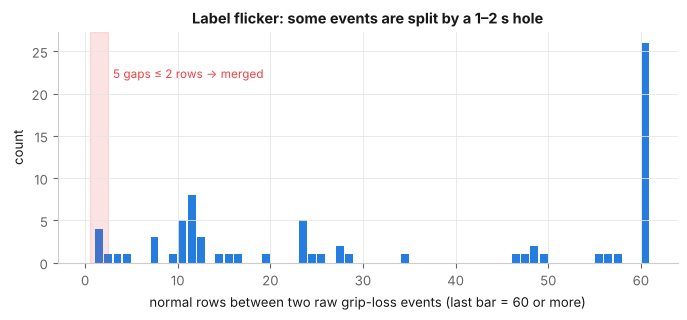

In [20]:
gl = df["GL_raw"].to_numpy()
on = np.where((gl == 1) & (np.r_[0, gl[:-1]] == 0))[0]
off = np.where((gl == 1) & (np.r_[gl[1:], 0] == 0))[0]
gaps = on[1:] - off[:-1] - 1
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(np.clip(gaps, 0, 60), bins=range(0, 62, 1), color=P.BLUE, rwidth=.85)
ax.axvspan(0.5, C.MERGE_GAP + .5, color=P.RED, alpha=.15)
ax.text(C.MERGE_GAP + 1, ax.get_ylim()[1] * .8, f"{int((gaps <= C.MERGE_GAP).sum())} gaps ≤ {C.MERGE_GAP} rows → merged", color=P.RED, fontsize=8.5)
ax.set_xlabel("normal rows between two raw grip-loss events (last bar = 60 or more)"); ax.set_ylabel("count")
ax.set_title("Label flicker: some events are split by a 1–2 s hole")
P.save(fig, "s1_fig07_event_gaps.png")

**Reading:** 5 gaps between raw grip-loss episodes are only 1–2 normal rows long; all the other gaps are longer.

*Implications:* these holes are treated as label flicker and filled (`MERGE_GAP = 2`, 77 → 72 events); otherwise the hole would create a new, trivially easy "event" right after a loss. The team must confirm this rule against the physical meaning of the `grip_lost` signal.

### 1.10 Pre-processing proposal
Everything that is *learned from data* is fitted inside the pipeline on the training fold; the other steps are
deterministic and can be applied to the whole time line without leakage.

In [21]:
prep = pd.DataFrame([
    ("Clean names, types, quoted timestamps", "Format problems only", "-", "all rows"),
    ("Drop Unnamed columns, Num", "Empty or identifier", "-", "all rows"),
    ("Keep empty rows in the time line; set placeholder Current_J0 = 1.0 to NaN", "Removing them glues events together and shifts lags", "-", "all rows"),
    (f"Causal forward fill of sensors (<= {C.FFILL_LIMIT} s, within segment)", "What a real-time system can do; no future value used", "-", "all rows"),
    ("Segments at breaks > 5 s; no window or label across them", "Avoid mixing two sessions in a window", "-", "all rows"),
    (f"Debounce label: merge events separated by <= {C.MERGE_GAP} rows", "1-2 s holes are label flicker, not a new loss; prevents trivially easy positives", "-", "label"),
    (f"Early-warning target y = onset in (t, t+{C.HORIZON}]", "Predicting the current second detects consequences (leakage)", "-", "label"),
    ("Remove rows where a loss is ongoing", "The alert must come before the loss", "-", "label"),
    ("6 temperatures -> mean + 60 s warm-up rate", f"Pearson r ≥ 0.99, VIF up to {vif_before.max():.0f}; PC1 = {100 * pca_t.explained_variance_ratio_[0]:.1f} %", "-", "features"),
    ("Exclude Robot_ProtectiveStop, cycle counter, timestamp", "Other label / encodes time", "-", "features"),
    ("Lags, differences, rolling mean/std (past 5 s)", "Precursors are short (1-6 s)", "-", "features"),
    ("Residual to the normal cycle profile at the same position", "Removes the cycle shape; signal = deviation", "training fold", "features (in pipeline)"),
    ("Position in cycle (raw for trees, spline for linear models)", "Strong non-monotonic risk profile", "training fold (spline)", "features (in pipeline)"),
    ("Median imputation of remaining NaN", "Robust to heavy tails", "training fold", "pipeline"),
    ("StandardScaler or RobustScaler (chosen by AutoML)", "Heavy-tailed currents (high kurtosis)", "training fold", "pipeline"),
    ("Class weights instead of SMOTE", "SMOTE interpolates between non-independent seconds", "training fold", "pipeline"),
    ("No outlier removal", "All values physically plausible (|speed| <= 2.73 rad/s < UR3 limit 3.14 rad/s, temps 28-45 °C); "
                           "<= 1.5 % of values beyond 5 sd and they are start/stop dynamics, i.e. signal", "-", "-"),
], columns=["step", "justification", "fitted on", "applies to"])
prep.to_csv(C.TAB / "s1_preprocessing_proposal.csv", index=False)
print("Step 1 done ->", C.TAB)
prep

Step 1 done -> /home/claude/repo/step2_standard_solutions/outputs_notebook/tables


,step,justification,fitted on,applies to
0,"Clean names, types, quoted timestamps",Format problems only,-,all rows
1,"Drop Unnamed columns, Num",Empty or identifier,-,all rows
2,Keep empty rows in the time line; set placeholder Current_J0 = 1.0 to NaN,Removing them glues events together and shifts lags,-,all rows
3,"Causal forward fill of sensors (<= 2 s, within segment)",What a real-time system can do; no future value used,-,all rows
4,Segments at breaks > 5 s; no window or label across them,Avoid mixing two sessions in a window,-,all rows
5,Debounce label: merge events separated by <= 2 rows,"1-2 s holes are label flicker, not a new loss; prevents trivially easy posit...",-,label
6,"Early-warning target y = onset in (t, t+3]",Predicting the current second detects consequences (leakage),-,label
7,Remove rows where a loss is ongoing,The alert must come before the loss,-,label
8,6 temperatures -> mean + 60 s warm-up rate,"Pearson r ≥ 0.99, VIF up to 8988; PC1 = 99.9 %",-,features
9,"Exclude Robot_ProtectiveStop, cycle counter, timestamp",Other label / encodes time,-,features


## Step 2 — Learning and testing plan
Choice of data and construction of the sets, cross-validation for tuning, diagnosis of under/over-fitting, and two
experiments that measure what data leakage would do to the scores.

In [22]:
# D (cleaned data, features and split) was built once in section A.7
df, X, part = D.df, D.X, D.part
Xtr, ytr, dtr = D.get("train")

### 2.1 Chronological train / validation / test sets
The data is one time series: random splits would put neighbouring seconds of the same cycle in train and test.
Cuts at 70 % and 85 % of the predictable rows, moved to the next cycle start, with an 8-row embargo.

       set  rows  positives (y=1)  prevalence %  events announced  cycles start (UTC) end (UTC)  mean temp J0 (°C)
0    train  4961              149          3.00                50     183    08:17:25  14:58:51               34.0
1  embargo    14                2         14.29                 1       2    14:58:52  15:17:49               37.1
2      val  1061               32          3.02                12      36    14:59:00  15:17:41               37.1
3     test  1046               26          2.49                 9      30    15:17:50  15:36:03               37.2


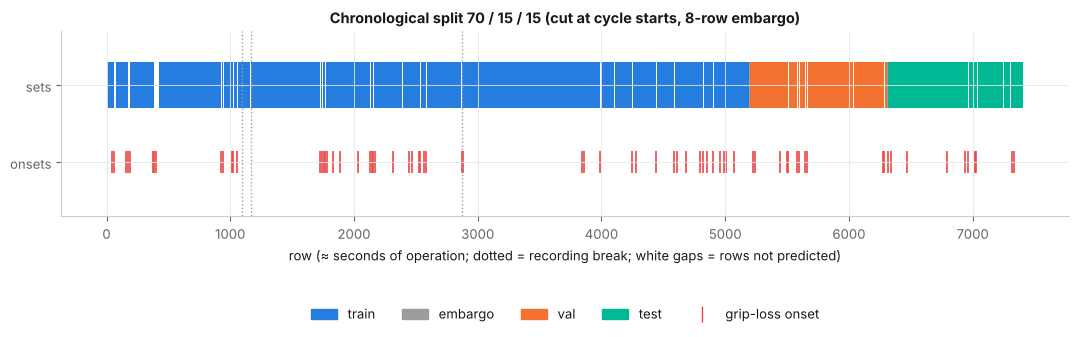

In [23]:
summary = split_summary(df, part)
summary.to_csv(C.TAB / "s2_split_summary.csv", index=False)
print(summary.to_string())

fig, ax = plt.subplots(figsize=(13, 2.4))
idx = np.arange(len(df))
pv = part.fillna("none").to_numpy()
start = 0
for i in range(1, len(pv) + 1):                      # draw contiguous runs of each set
    if i == len(pv) or pv[i] != pv[start]:
        if pv[start] in P.SET_COLORS:
            ax.broken_barh([(start, i - start)], (.7, .6), color=P.SET_COLORS[pv[start]], lw=0)
        start = i
ax.scatter(idx[df["onset"]], np.full(df["onset"].sum(), 0.0), marker="|", s=250, color=P.RED, lw=1.2)
for b in idx[df["segment"].diff() > 0]:
    ax.axvline(b, color=P.GRAY, ls=":", lw=1)
ax.set_ylim(-.7, 1.7); ax.set_yticks([0, 1], ["onsets", "sets"])
ax.set_xlabel("row (≈ seconds of operation; dotted = recording break; white gaps = rows not predicted)")
handles = [Patch(color=P.SET_COLORS[k], label=k) for k in ["train", "embargo", "val", "test"]]
handles.append(plt.Line2D([], [], color=P.RED, marker="|", ls="", ms=12, label="grip-loss onset"))
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(.5, -.42), ncol=5)
ax.set_title("Chronological split 70 / 15 / 15 (cut at cycle starts, 8-row embargo)")
P.save(fig, "s2_fig01_split_timeline.png")

**Reading:**
- train = 4,961 rows (50 events): the whole morning and the start of the afternoon;
- validation = 1,061 rows (12 events) and test = 1,046 rows (9 events), both at the warm end of the afternoon (mean temperature 37 °C, against 34 °C in train);
- the embargo removes 14 rows.

*Implications:* one missed test event changes the event recall by 11 points: every test figure comes with a cycle-bootstrap confidence interval. Train and test are not in the same thermal regime, one more reason to be careful with the temperature.

### 2.2 Cross-validation folds inside the training period
Plain `TimeSeriesSplit` (equal rows) vs our event-balanced expanding window (equal events).

In [24]:
# (a) plain TimeSeriesSplit: equal rows per fold -> one fold holds a single event
# (b) event-balanced expanding window: equal events per fold (used for all tuning)
def fold_table(cv_iter, scheme):
    rows = []
    for k, (a, b) in enumerate(cv_iter):
        rows.append({"scheme": scheme, "fold": k + 1, "train rows": len(a), "validation rows": len(b),
                     "train events": dtr.iloc[a]["target_event"].nunique(),
                     "validation positives": int(ytr.iloc[b].sum()),
                     "validation events": dtr.iloc[b]["target_event"].nunique(),
                     "validation period (UTC)": f"{dtr.iloc[b]['ts'].min():%H:%M}-{dtr.iloc[b]['ts'].max():%H:%M}"})
    return rows


cv = event_balanced_cv(dtr["target_event"])
folds = pd.DataFrame(fold_table(ts_cv().split(Xtr), "TimeSeriesSplit (equal rows)")
                     + fold_table(cv, "Event-balanced (used)"))
folds.to_csv(C.TAB / "s2_cv_folds.csv", index=False)
print(folds.to_string())
folds = folds[folds["scheme"] == "Event-balanced (used)"].reset_index(drop=True)

                         scheme  fold  train rows  validation rows  train events  validation positives  validation events validation period (UTC)
0  TimeSeriesSplit (equal rows)     1         823              826             8                    27                  9             08:32-08:47
1  TimeSeriesSplit (equal rows)     2        1649              826            17                    45                 15             08:47-09:02
2  TimeSeriesSplit (equal rows)     3        2475              826            32                     3                  1             09:02-14:30
3  TimeSeriesSplit (equal rows)     4        3301              826            33                    15                  5             14:30-14:44
4  TimeSeriesSplit (equal rows)     5        4127              826            38                    35                 12             14:44-14:58
5         Event-balanced (used)     1         844              792             8                    24                  8   

**Reading:**
- with equal rows (`TimeSeriesSplit`), **fold 3 contains one event (3 positive rows)** because it covers the lunch break;
- the event-balanced folds hold **8–9 events each**, with validation blocks of 485 to 1,500 rows.

*Implications:* a fold with one event gives a meaningless PR-AUC that dominates the variance. The event-balanced folds are used for all tuning in Steps 3 and 5.

### 2.3 Under- and over-fitting: expanding-window learning curves
PR-AUC on the training fold vs on the next (future) fold as the training window grows, for a linear model, an
unconstrained forest and a forest with large leaves.

                                      train PR-AUC  CV PR-AUC
model                                                        
Logistic regression (C = 0.1)                0.349      0.205
Random forest, min_samples_leaf = 30         0.950      0.307
Random forest, unconstrained                 1.000      0.359


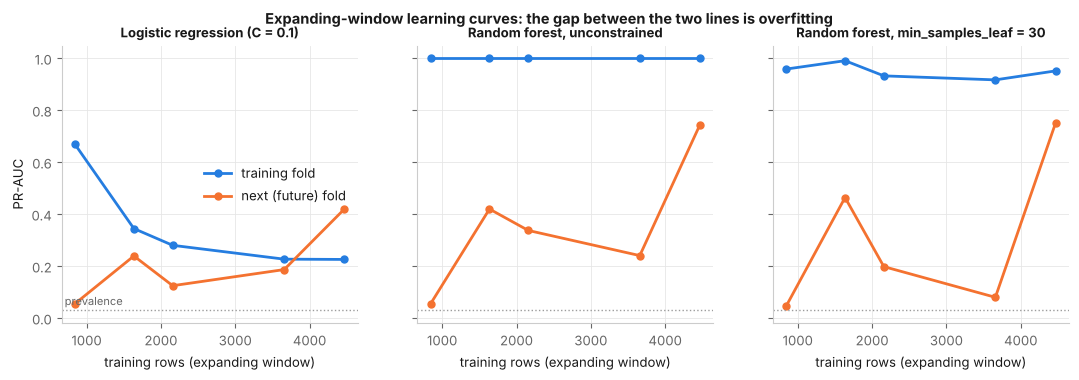

In [25]:
cands = {
    "Logistic regression (C = 0.1)": make_pipeline(
        LogisticRegression(C=0.1, class_weight="balanced", max_iter=3000), pos_encoding="spline"),
    "Random forest, unconstrained": make_pipeline(
        RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=C.SEED)),
    "Random forest, min_samples_leaf = 30": make_pipeline(
        RandomForestClassifier(n_estimators=200, min_samples_leaf=30, max_features=0.3,
                               class_weight="balanced_subsample", n_jobs=-1, random_state=C.SEED)),
}
lc_rows = []
for name, pipe in cands.items():
    res = cross_validate(pipe, Xtr, ytr, cv=cv, scoring="average_precision", return_train_score=True)
    for k in range(len(res["test_score"])):
        lc_rows.append({"model": name, "fold": k + 1, "train rows": folds.loc[k, "train rows"],
                        "train PR-AUC": res["train_score"][k], "CV PR-AUC": res["test_score"][k]})
lc = pd.DataFrame(lc_rows)
lc.round(3).to_csv(C.TAB / "s2_learning_curves.csv", index=False)
print(lc.groupby("model")[["train PR-AUC", "CV PR-AUC"]].mean().round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (name, g) in zip(axes, lc.groupby("model", sort=False)):
    ax.plot(g["train rows"], g["train PR-AUC"], marker="o", ms=5, color=P.BLUE, label="training fold")
    ax.plot(g["train rows"], g["CV PR-AUC"], marker="o", ms=5, color=P.ORANGE, label="next (future) fold")
    ax.axhline(ytr.mean(), color=P.GRAY, ls=":", lw=1)
    ax.set_title(name, fontsize=9.5); ax.set_xlabel("training rows (expanding window)")
axes[0].set_ylabel("PR-AUC"); axes[0].text(axes[0].get_xlim()[0], ytr.mean() + .02, " prevalence", color=P.INK2, fontsize=8)
axes[0].legend(loc="center right")
fig.suptitle("Expanding-window learning curves: the gap between the two lines is overfitting", fontweight="bold", fontsize=10.5)
P.save(fig, "s2_fig02_learning_curves.png")

**Reading:**
- **underfitting**: the logistic regression has train 0.35 and CV 0.21, both low and close;
- **overfitting**: the unconstrained forest has train 1.0 and CV 0.36; larger leaves reduce the gap but also the CV score (0.31);
- the future-fold score rises in the last folds.

*Implications:* the linear model cannot represent the interactions between the cycle position and the currents → richer features or non-linear models. With ~50 events the limit is the data, so the regularisation strength must be a hyper-parameter chosen by CV. More history helps: argument for re-training on train + validation before deployment.

### 2.4 Leakage experiment A — shuffled K-fold vs time-series CV
Same random forest, same training rows, two validation schemes (results shown with experiment B in section 2.5).

In [26]:
rf = cands["Random forest, min_samples_leaf = 30"]
leak = []
for label, splitter in [("Shuffled stratified 5-fold (rows treated as independent)",
                         StratifiedKFold(5, shuffle=True, random_state=C.SEED)),
                        ("Expanding-window time-series CV, gap = 8 (our protocol)", cv)]:
    s = cross_validate(rf, Xtr, ytr, cv=splitter, scoring="average_precision")["test_score"]
    leak.append({"experiment": "A: validation scheme", "variant": label, "mean CV PR-AUC": s.mean(), "sd": s.std(),
                 "folds": np.round(s, 3).tolist()})

### 2.5 Leakage experiment B — centred vs causal rolling windows
A centred 5-s window uses t+1 and t+2: it looks 2 s into the future.

                experiment                                                   variant  mean CV PR-AUC     sd                                folds
0     A: validation scheme  Shuffled stratified 5-fold (rows treated as independent)           0.376  0.091  [0.454, 0.396, 0.254, 0.289, 0.487]
1     A: validation scheme   Expanding-window time-series CV, gap = 8 (our protocol)           0.307  0.266    [0.046, 0.464, 0.198, 0.08, 0.75]
2  B: feature construction        Centred rolling windows (look 2 s into the future)           0.406  0.185  [0.101, 0.543, 0.449, 0.311, 0.624]
3  B: feature construction          Causal rolling windows (past only, our protocol)           0.307  0.266    [0.046, 0.464, 0.198, 0.08, 0.75]


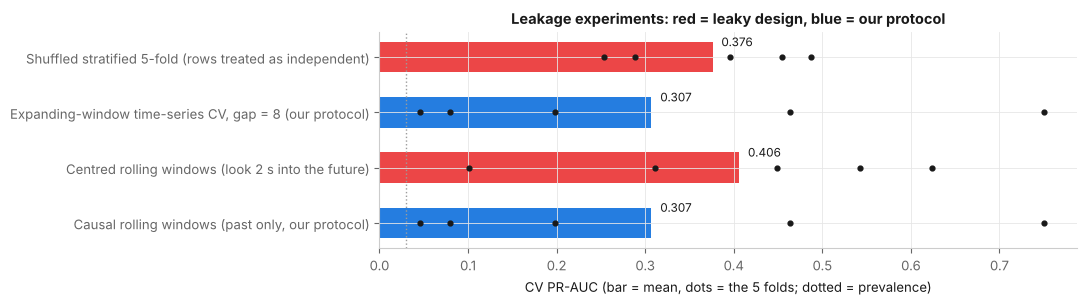

Step 2 done


In [27]:
Xc = X.copy()
for col in DYN:
    Xc[f"{col}_rmean{C.WINDOW}"] = X.groupby(df["segment"])[col].transform(
        lambda v: v.rolling(C.WINDOW, center=True, min_periods=1).mean())
    Xc[f"{col}_rstd{C.WINDOW}"] = X.groupby(df["segment"])[col].transform(
        lambda v: v.rolling(C.WINDOW, center=True, min_periods=2).std())
for label, XX in [("Centred rolling windows (look 2 s into the future)", Xc.loc[Xtr.index]),
                  ("Causal rolling windows (past only, our protocol)", Xtr)]:
    s = cross_validate(rf, XX, ytr, cv=cv, scoring="average_precision")["test_score"]
    leak.append({"experiment": "B: feature construction", "variant": label, "mean CV PR-AUC": s.mean(), "sd": s.std(),
                 "folds": np.round(s, 3).tolist()})
leak = pd.DataFrame(leak).round(3)
leak.to_csv(C.TAB / "s2_leakage_experiments.csv", index=False)
print(leak.to_string())

fig, ax = plt.subplots(figsize=(9, 2.8))
yy = np.arange(len(leak))[::-1]
cols = [P.RED if ("Shuffled" in v or "Centred" in v) else P.BLUE for v in leak["variant"]]
ax.barh(yy, leak["mean CV PR-AUC"], color=cols, height=.55)
for y_, f in zip(yy, leak["folds"]):
    ax.scatter(f, np.full(len(f), y_), s=12, color=P.INK, zorder=3)
ax.set_yticks(yy, leak["variant"])
for y_, v in zip(yy, leak["mean CV PR-AUC"]):
    ax.text(v + .01, y_ + .2, f"{v:.3f}", fontsize=8.5)
ax.axvline(ytr.mean(), color=P.GRAY, ls=":", lw=1)
ax.set_xlabel("CV PR-AUC (bar = mean, dots = the 5 folds; dotted = prevalence)")
ax.set_title("Leakage experiments: red = leaky design, blue = our protocol")
P.save(fig, "s2_fig03_leakage_experiments.png")
print("Step 2 done")

**Reading:**
- **experiment A**: shuffled K-fold inflates the PR-AUC by **+22 %** (0.376 vs 0.307) and hides the variation between periods (sd 0.09 vs 0.27);
- **experiment B**: centred windows inflate it by **+32 %** (0.406 vs 0.307).

*Implications:* both designs would look like progress and disappear in deployment. We keep causal windows and the time-series CV.

**Leakage checklist applied in this notebook:** causal features only; ongoing-loss rows removed; everything learned from data inside the pipeline (refitted per fold); chronological sets with embargo; expanding-window CV with a gap; decision statistics on the training period only; test period evaluated once.

**Evaluation methods:** PR-AUC (ranking), event recall + warning time + false alarms per hour (alerts), two operating points chosen on validation (F1-optimal and ≤ 30 false alarms per hour), 95 % cycle-bootstrap intervals and paired comparisons.

## Step 3 — Baseline solution and its calibration
Three reference levels: **B0** prior (constant score — the zero of the PR-AUC scale), **B1** risk per second of the
cycle (domain baseline, no sensor), **B2** logistic regression on the current-second signals + mean temperature +
spline of the position in the cycle (the baseline proper: simple, fast, interpretable).
Calibration of B2 = (1) regularisation C chosen by time-series CV, (2) probability calibration, (3) decision threshold
chosen on validation.

In [28]:
# D (cleaned data, features and split) was built once in section A.7
Xtr, ytr, dtr = D.get("train")
Xva, yva, dva = D.get("val")
Xte, yte, dte = D.get("test")
cv = event_balanced_cv(dtr["target_event"])

### 3.1 B0 and B1

In [29]:
b0 = PriorBaseline().fit(Xtr, ytr)
b1 = CyclePositionBaseline().fit(Xtr, ytr)

### 3.2 Choice of C (validation curve)
C is searched over 13 values from 1e-4 to 1e2 on the event-balanced CV. With ~8 events per fold the fold-to-fold
standard error is larger than the whole curve, so the classical one-standard-error rule would always pick the
strongest penalty. Because every C uses the same folds, we apply the rule to the **paired** fold differences.

          C  train mean  CV mean  CV se  paired diff to best  paired se
0     0.000       0.103    0.080  0.023               -0.049      0.022
1     0.000       0.107    0.082  0.024               -0.047      0.020
2     0.001       0.114    0.086  0.025               -0.043      0.018
3     0.003       0.124    0.093  0.028               -0.036      0.016
4     0.010       0.134    0.103  0.032               -0.026      0.011
5     0.032       0.152    0.113  0.033               -0.016      0.011
6     0.100       0.163    0.120  0.038               -0.009      0.006
7     0.316       0.162    0.129  0.043                0.000      0.000
8     1.000       0.160    0.128  0.042               -0.001      0.002
9     3.162       0.158    0.127  0.042               -0.002      0.003
10   10.000       0.154    0.124  0.040               -0.005      0.005
11   31.623       0.155    0.123  0.039               -0.006      0.006
12  100.000       0.153    0.122  0.039               -0.007    

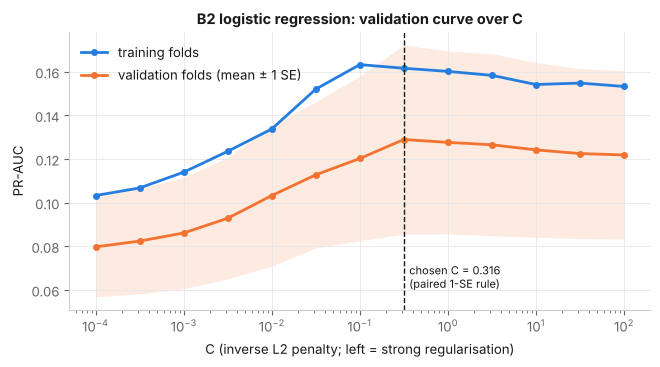

In [30]:
def lr_pipe(C_=1.0, cw="balanced"):
    return make_pipeline(LogisticRegression(C=C_, class_weight=cw, max_iter=5000),
                         window=False, residual=False, burst=False, temperature="mean", pos_encoding="spline")


grid = np.logspace(-4, 2, 13)
tr_s, cv_s = validation_curve(lr_pipe(), Xtr, ytr, param_name="model__C", param_range=grid,
                              cv=cv, scoring="average_precision")
vc = pd.DataFrame({"C": grid, "train mean": tr_s.mean(1), "CV mean": cv_s.mean(1),
                   "CV se": cv_s.std(1, ddof=1) / np.sqrt(cv_s.shape[1])})
best = int(vc["CV mean"].idxmax())
# One-standard-error rule on *paired* fold differences: the folds are the same for every C,
# so the fold-to-fold variance (very large here, ~8 events per fold) cancels out. The plain
# 1-SE rule (unpaired SE) would always pick the strongest penalty of the grid.
diff = cv_s - cv_s[best]
vc["paired diff to best"] = diff.mean(1)
vc["paired se"] = diff.std(1, ddof=1) / np.sqrt(diff.shape[1])
ok = vc["paired diff to best"] >= -vc["paired se"].fillna(0)
C_chosen = float(vc.loc[ok, "C"].min())
C_unpaired = float(vc.loc[vc["CV mean"] >= vc.loc[best, "CV mean"] - vc.loc[best, "CV se"], "C"].min())
vc.round(4).to_csv(C.TAB / "s3_validation_curve_C.csv", index=False)
print(vc.round(3).to_string(), "\nC with best CV:", vc.loc[best, "C"], "| C chosen (paired 1-SE):", C_chosen,
      "| plain 1-SE would give:", C_unpaired)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(grid, vc["train mean"], marker="o", ms=4, color=P.BLUE, label="training folds")
ax.plot(grid, vc["CV mean"], marker="o", ms=4, color=P.ORANGE, label="validation folds (mean ± 1 SE)")
ax.fill_between(grid, vc["CV mean"] - vc["CV se"], vc["CV mean"] + vc["CV se"], color=P.ORANGE, alpha=.15, lw=0)
ax.axvline(C_chosen, color=P.INK, ls="--", lw=1)
ax.text(C_chosen * 1.15, ax.get_ylim()[0] + .01, f"chosen C = {C_chosen:.3g}\n(paired 1-SE rule)", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("C (inverse L2 penalty; left = strong regularisation)"); ax.set_ylabel("PR-AUC")
ax.set_title("B2 logistic regression: validation curve over C"); ax.legend(loc="upper left")
P.save(fig, "s3_fig01_validation_curve.png")

b2 = lr_pipe(C_chosen).fit(Xtr, ytr)

**Reading:**
- the CV PR-AUC rises up to **C = 0.316** (0.129) and is flat above C = 0.1;
- the plain one-standard-error rule would pick C = 0.001 (no skill on validation); the paired rule keeps C = 0.316.

*Implications:* B2 uses C = 0.316. With so few events per fold, model-selection rules must compare candidates on the **same folds** (paired differences).

### 3.3 Probability calibration (validation period)
Balanced class weights multiply the weight of positives by ~16 and inflate the probabilities. Compared: balanced
weights, no weights, balanced + sigmoid (Platt) recalibration fitted on the time-series folds.

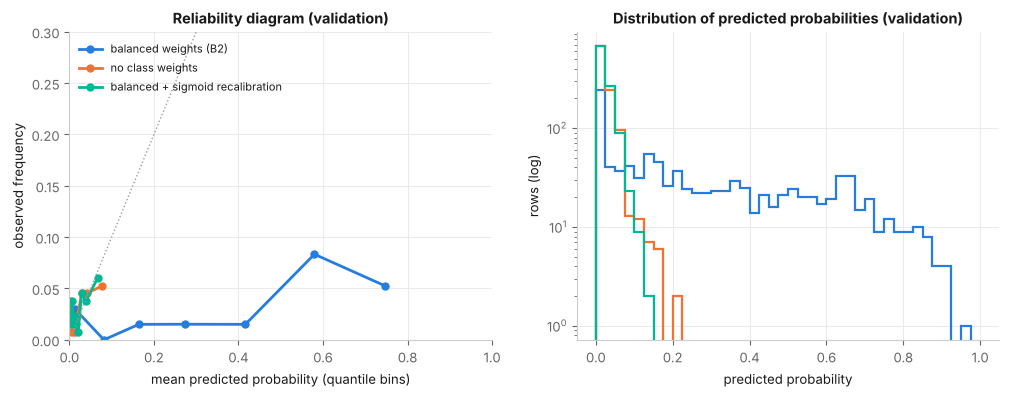

                            variant  PR-AUC   Brier  log-loss  mean predicted %  observed rate %
0             balanced weights (B2)  0.0600  0.1535    0.4653           28.4249            3.016
1                  no class weights  0.0488  0.0294    0.1467            2.3809            3.016
2  balanced + sigmoid recalibration  0.0494  0.0293    0.1392            2.3805            3.016


In [31]:
variants = {
    "balanced weights (B2)": b2,
    "no class weights": lr_pipe(C_chosen, cw=None).fit(Xtr, ytr),
    "balanced + sigmoid recalibration": CalibratedClassifierCV(lr_pipe(C_chosen), method="sigmoid", cv=cv).fit(Xtr, ytr),
}
cal_rows = []
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for (name, m), col in zip(variants.items(), [P.BLUE, P.ORANGE, P.AQUA]):
    p = m.predict_proba(Xva)[:, 1]
    cal_rows.append({"variant": name, "PR-AUC": average_precision_score(yva, p), "Brier": brier_score_loss(yva, p),
                     "log-loss": log_loss(yva, p), "mean predicted %": 100 * p.mean(), "observed rate %": 100 * yva.mean()})
    frac, mean_p = calibration_curve(yva, p, n_bins=8, strategy="quantile")
    ax[0].plot(mean_p, frac, marker="o", ms=5, color=col, label=name)
    ax[1].hist(p, bins=np.linspace(0, 1, 41), histtype="step", lw=1.6, color=col, label=name)
ax[0].plot([0, 1], [0, 1], color=P.GRAY, ls=":", lw=1)
ax[0].set_xlim(0, 1); ax[0].set_ylim(0, .3)
ax[0].set_xlabel("mean predicted probability (quantile bins)"); ax[0].set_ylabel("observed frequency")
ax[0].set_title("Reliability diagram (validation)"); ax[0].legend(loc="upper left", fontsize=8)
ax[1].set_yscale("log"); ax[1].set_xlabel("predicted probability"); ax[1].set_ylabel("rows (log)")
ax[1].set_title("Distribution of predicted probabilities (validation)")
P.save(fig, "s3_fig02_calibration.png")
cal = pd.DataFrame(cal_rows).round(4)
cal.to_csv(C.TAB / "s3_calibration.csv", index=False)
print(cal.to_string())

**Reading:**
- *balanced weights*: mean prediction 28 % for an observed rate of 3 % (Brier 0.154): the probabilities are inflated;
- *no weights* or *sigmoid recalibration* bring it back to ≈ 2.4 % (Brier 0.029) but slightly lower the PR-AUC (0.049 vs 0.060).

*Implications:* alerts depend only on the ranking and on a threshold tuned on validation, so B2 keeps balanced weights. The recalibrated version is the one to use if probabilities are shown to an operator.

### 3.4 Thresholds (validation) and results (test, used once)
Two operating points chosen on validation: F1-optimal and ≤ 30 false alarms per hour.

In [32]:
models = {"B0 prior": b0, "B1 cycle position": b1, "B2 logistic regression": b2}
res, scores_out = [], {}
for name, m in models.items():
    s_va = m.predict_proba(Xva)[:, 1]
    s_te = m.predict_proba(Xte)[:, 1]
    thr_f1 = best_f1_threshold(yva, s_va) if name != "B0 prior" else 0.5
    thr_fa = fa_constrained_threshold(dva, s_va, C.MAX_FA_PER_HOUR) if name != "B0 prior" else 0.5
    scores_out[name] = (s_va, s_te, thr_f1, thr_fa)
    for op, thr in [("F1-optimal", thr_f1), (f"<= {C.MAX_FA_PER_HOUR:g} FA/h", thr_fa)]:
        if name == "B0 prior" and op != "F1-optimal":
            continue
        for set_name, y_, d_, s_ in [("val", yva, dva, s_va), ("test", yte, dte, s_te)]:
            r = {"model": name, "operating point": op, "set": set_name, "threshold": thr}
            r.update(row_metrics(y_, s_, thr))
            r.update(event_metrics(d_, s_, thr))
            if set_name == "test" and name != "B0 prior":
                _, lo, hi = bootstrap_ci(d_, s_, average_precision_score, n_boot=C.N_BOOT)
                r["PR-AUC 95% CI"] = f"[{lo:.3f}, {hi:.3f}]"
                _, lo, hi = bootstrap_event_recall(d_, s_, thr, n_boot=C.N_BOOT)
                r["event recall 95% CI"] = f"[{lo:.2f}, {hi:.2f}]"
            res.append(r)
res = pd.DataFrame(res)
res.round(4).to_csv(C.TAB / "s3_baseline_results.csv", index=False)
print(res[["model", "operating point", "set", "threshold", "PR-AUC", "ROC-AUC", "precision", "recall", "F1", "event recall",
           "mean warning (s)", "false alarms / hour"]].round(3).to_string())

                    model operating point   set  threshold  PR-AUC  ROC-AUC  precision  recall     F1  event recall  mean warning (s)  false alarms / hour
0                B0 prior      F1-optimal   val      0.500   0.030    0.500      0.000   0.000  0.000         0.000               NaN                0.000
1                B0 prior      F1-optimal  test      0.500   0.025    0.500      0.000   0.000  0.000         0.000               NaN                0.000
2       B1 cycle position      F1-optimal   val      0.048   0.035    0.550      0.043   0.406  0.078         0.667             2.390              335.910
3       B1 cycle position      F1-optimal  test      0.048   0.066    0.755      0.061   0.615  0.111         0.778             2.872              302.868
4       B1 cycle position      <= 30 FA/h   val      0.078   0.035    0.550      0.000   0.000  0.000         0.000               NaN                0.000
5       B1 cycle position      <= 30 FA/h  test      0.078   0.066    

**Reading:**
- test PR-AUC: **B1 0.066** [0.022, 0.136] and **B2 0.057** [0.025, 0.132], for a prevalence of 0.025;
- at the F1-optimal threshold, B2 anticipates 6 of 9 test events but with **341 false alarms per hour** (one every 10 s);
- at ≤ 30 false alarms per hour, B2 anticipates **1 event out of 9** and B1 none.

*Implications:* the baselines are useless in operation, and B2 does not beat the cycle position alone: the current-second signals add little without past windows. This is the level the AutoML must beat.

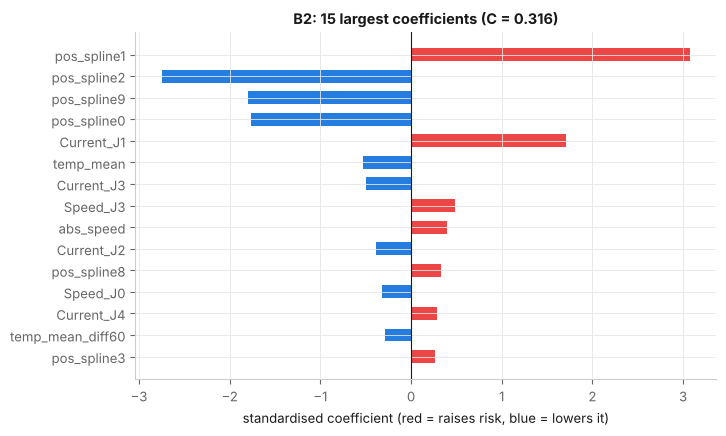

Step 3 done


In [32]:
# coefficients of B2 (standardised features)
names = b2.named_steps["features"].get_feature_names_out()
coef = pd.Series(b2.named_steps["model"].coef_[0], index=names)
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.barh(top.index, top.values, color=[P.RED if v > 0 else P.BLUE for v in top.values], height=.6)
ax.axvline(0, color=P.INK, lw=.8)
ax.set_xlabel("standardised coefficient (red = raises risk, blue = lowers it)")
ax.set_title(f"B2: 15 largest coefficients (C = {C_chosen:.3g})")
P.save(fig, "s3_fig03_coefficients.png")

# keep scores for the comparison in step 5
out = []
for name, (s_va, s_te, thr_f1, thr_fa) in scores_out.items():
    for set_name, idx, sc in [("val", Xva.index, s_va), ("test", Xte.index, s_te)]:
        out.append(pd.DataFrame({"row": idx, "set": set_name, "model": name, "score": sc,
                                 "thr_f1": thr_f1, "thr_fa": thr_fa}))
pd.concat(out).to_csv(C.MODELS / "baseline_scores.csv", index=False)
joblib.dump({"B1": b1, "B2": b2, "C": C_chosen}, C.MODELS / "baselines.joblib")
print("Step 3 done")

**Reading:**
- the largest coefficients are the **spline terms of the position in the cycle** (up to ±3): the risk profile along the cycle dominates the model;
- among the sensors, **Current_J1** has the largest positive weight (+1.7: a higher shoulder current raises the risk), then the mean temperature (−0.5: a colder robot raises the risk), Current_J3 (−0.5) and Speed_J3 (+0.5).

*Implications:* B2 is mostly a smoothed version of B1 (risk per second of the cycle) plus the shoulder current, consistent with Step 1. Its negative temperature weight is the cold-start confounding, which does not transfer to the warm test period.

## Step 4 — Benchmark models from the state of the art
Published results on UR3 CobotOps, then a re-run of their **protocols** on our data with the same model families, to
see how much of the published performance comes from the protocol rather than from the model.

### 4.1 Published results (verified sources; Liu 2025 figures from our Step-1 review, to be re-checked)

In [33]:
lit = pd.DataFrame([
    ("Tyrovolas et al. (2024) – dataset authors", "fault diagnosis (both labels)", "Information-Flow Fuzzy Cognitive Maps (interpretable)",
     "not compared (interpretability study)", "-", "-"),
    ("Liu (2025), Engineering Frontiers", "combined fault (protective stop OR grip loss), current second",
     "LR, SVM, RF, k-NN, decision tree", "random 70/30, fixed seed", "RF: ROC-AUC 0.911; k-NN: best F1 0.446; LR detects no fault",
     "figures from our Step-1 review, paper page not reachable for re-check"),
    ("Yaşar Çıklaçandır et al. (2025), DEU FMD", "grip_lost (and protective stop) separately, current second",
     "LR, DT, RF, SVM, k-NN; RFE / chi-square selection; StandardScaler + SMOTE", "70/30 (random vs chronological not stated)",
     "grip_lost, RF: accuracy 0.990, precision 0.986, recall 0.994, F1 0.990, ROC-AUC 0.990 (0.999 after chi-square)",
     "precision ≈ recall ≈ accuracy suggests a balanced (oversampled) test set"),
    ("Taş & Bal (2025), Sakarya Univ. J. Sci.", "protective stop, current second", "ESOA-tuned BiRNN vs CNN, LSTM, BiLSTM, GRU, TCN, CNN-RNN",
     "random 80/20", "ESOA-BiRNN: ROC-AUC 0.946, accuracy 0.892, precision 0.280, recall 0.853, F1 0.422", "other target (protective stop)"),
    ("Shen et al. (2026), PHM Asia-Pacific", "fault classification + RUL", "physics-informed Transformer (PhysODE-Joint)",
     "not stated on the abstract page", "no numbers on the abstract page", "cites UR3 CobotOps; full paper to be read"),
], columns=["study", "target", "models", "split", "reported results", "remark"])
lit.to_csv(C.TAB / "s4_literature.csv", index=False)
lit

,study,target,models,split,reported results,remark
0,Tyrovolas et al. (2024) – dataset authors,fault diagnosis (both labels),Information-Flow Fuzzy Cognitive Maps (interpretable),not compared (interpretability study),-,-
1,"Liu (2025), Engineering Frontiers","combined fault (protective stop OR grip loss), current second","LR, SVM, RF, k-NN, decision tree","random 70/30, fixed seed",RF: ROC-AUC 0.911; k-NN: best F1 0.446; LR detects no fault,"figures from our Step-1 review, paper page not reachable for re-check"
2,"Yaşar Çıklaçandır et al. (2025), DEU FMD","grip_lost (and protective stop) separately, current second","LR, DT, RF, SVM, k-NN; RFE / chi-square selection; StandardScaler + SMOTE",70/30 (random vs chronological not stated),"grip_lost, RF: accuracy 0.990, precision 0.986, recall 0.994, F1 0.990, ROC-...",precision ≈ recall ≈ accuracy suggests a balanced (oversampled) test set
3,"Taş & Bal (2025), Sakarya Univ. J. Sci.","protective stop, current second","ESOA-tuned BiRNN vs CNN, LSTM, BiLSTM, GRU, TCN, CNN-RNN",random 80/20,"ESOA-BiRNN: ROC-AUC 0.946, accuracy 0.892, precision 0.280, recall 0.853, F1...",other target (protective stop)
4,"Shen et al. (2026), PHM Asia-Pacific",fault classification + RUL,physics-informed Transformer (PhysODE-Joint),not stated on the abstract page,no numbers on the abstract page,cites UR3 CobotOps; full paper to be read


**Reading:**
- all published scores concern the **current second** (the fault is already happening) and use random splits, or do not state the order;
- Yaşar Çıklaçandır et al. (2025) report accuracy ≈ precision ≈ recall ≈ F1 ≈ AUC ≈ 0.99 for `grip_lost`: what one expects when the test set itself was balanced, i.e. SMOTE applied before the split.

*Implications:* the published numbers are not comparable with our early-warning task. Section 4.2 re-runs their protocols on our data to measure the gap. The Liu (2025) figures must be re-checked before the report.

### 4.2 Re-running the published protocols on our data
P1 concurrent label + random 70/30 · P2 = P1 + SMOTE **before** the split · P3 = P1 + SMOTE on train only ·
P4 concurrent label + chronological 70/30 · P5 our early-warning task, chronological (train → validation).
Raw sensors, default hyper-parameters, threshold 0.5.

In [34]:
# D (cleaned data, features and split) was built once in section A.7
df, X = D.df, D.X
feats = C.SENSORS                              # raw sensors, as in the published studies
rows_ok = ~df["sensor_missing"]
Xc, yc = df.loc[rows_ok, feats], df.loc[rows_ok, "GL_raw"]       # concurrent label, all rows


def models():
    return {
        "Random forest": RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=C.SEED),
        "k-NN (k = 5)": sk_make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
        "Logistic regression": sk_make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    }


def evaluate(protocol, Xa, ya, Xb, yb):
    out = []
    for name, m in models().items():
        m.fit(Xa, ya)
        s = m.predict_proba(Xb)[:, 1]
        p = (s >= .5).astype(int)
        out.append({"protocol": protocol, "model": name, "test prevalence %": 100 * np.mean(yb),
                    "accuracy": accuracy_score(yb, p), "precision": precision_score(yb, p, zero_division=0),
                    "recall": recall_score(yb, p), "F1": f1_score(yb, p),
                    "ROC-AUC": roc_auc_score(yb, s), "PR-AUC": average_precision_score(yb, s)})
    return out


res = []
# P1 – concurrent label, random stratified 70/30 (Liu 2025 style)
a, b, ya, yb = train_test_split(Xc, yc, test_size=.3, stratify=yc, random_state=C.SEED)
res += evaluate("P1 concurrent label, random 70/30", a, ya, b, yb)
# P2 – SMOTE applied to the whole data set BEFORE the split (suspected in Yaşar Çıklaçandır 2025)
Xs, ys = SMOTE(random_state=C.SEED).fit_resample(StandardScaler().fit_transform(Xc), yc)
a2, bs2, ya2, yb2 = train_test_split(Xs, ys, test_size=.3, stratify=ys, random_state=C.SEED)
res += evaluate("P2 = P1 + SMOTE before the split", a2, ya2, bs2, yb2)
# P3 – SMOTE on the training part only (correct use)
a3, ya3 = SMOTE(random_state=C.SEED).fit_resample(a, ya)
res += evaluate("P3 = P1 + SMOTE on train only", a3, ya3, b, yb)
# P4 – concurrent label, chronological 70/30
cut = int(.7 * len(Xc))
res += evaluate("P4 concurrent label, chronological 70/30", Xc.iloc[:cut], yc.iloc[:cut], Xc.iloc[cut:], yc.iloc[cut:])
# P5 – our task: early warning N = 3 s, ongoing losses removed, chronological (train -> validation)
Xtr, ytr, _ = D.get("train")
Xva, yva, _ = D.get("val")
res += evaluate("P5 early warning N = 3 s, chronological (ours)", Xtr[feats].fillna(Xtr[feats].median()), ytr,
                Xva[feats].fillna(Xtr[feats].median()), yva)
res = pd.DataFrame(res)
res.round(3).to_csv(C.TAB / "s4_protocol_rerun.csv", index=False)
print(res.round(3).to_string())

                                          protocol                model  test prevalence %  accuracy  precision  recall     F1  ROC-AUC  PR-AUC
0                P1 concurrent label, random 70/30        Random forest              3.308     0.977      0.897   0.356  0.510    0.935   0.671
1                P1 concurrent label, random 70/30         k-NN (k = 5)              3.308     0.970      0.560   0.384  0.455    0.817   0.403
2                P1 concurrent label, random 70/30  Logistic regression              3.308     0.967      0.000   0.000  0.000    0.753   0.101
3                 P2 = P1 + SMOTE before the split        Random forest             50.000     0.983      0.976   0.989  0.983    0.999   0.999
4                 P2 = P1 + SMOTE before the split         k-NN (k = 5)             50.000     0.947      0.911   0.992  0.950    0.983   0.968
5                 P2 = P1 + SMOTE before the split  Logistic regression             50.000     0.709      0.708   0.714  0.711    0.778 

### 4.3 The same random forest under the five protocols

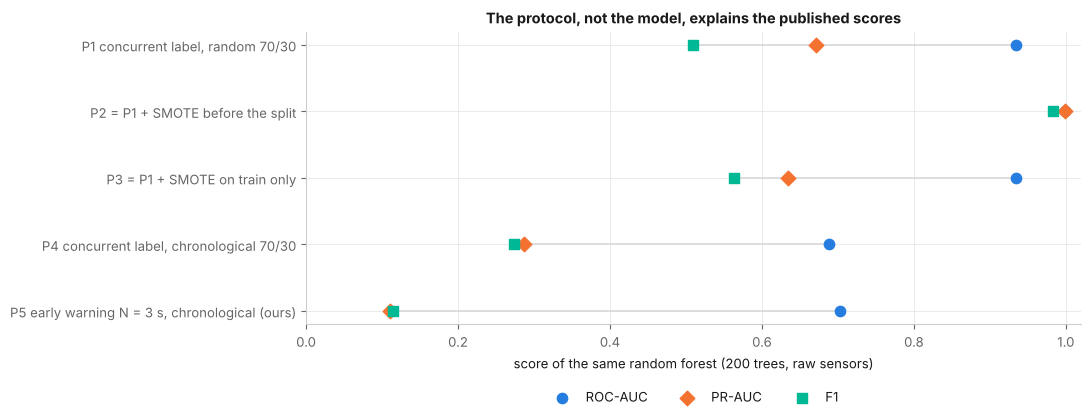

Step 4 done


In [35]:
rf = res[res["model"] == "Random forest"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 3.8))
yy = np.arange(len(rf))[::-1]
for metric, col, mk in [("ROC-AUC", P.BLUE, "o"), ("PR-AUC", P.ORANGE, "D"), ("F1", P.AQUA, "s")]:
    ax.scatter(rf[metric], yy, color=col, marker=mk, s=55, label=metric, zorder=3)
for k, y_ in enumerate(yy):
    ax.plot([rf.loc[k, ["ROC-AUC", "PR-AUC", "F1"]].min(), rf.loc[k, ["ROC-AUC", "PR-AUC", "F1"]].max()], [y_, y_],
            color="#d9d9d9", lw=1.2, zorder=2)
ax.set_yticks(yy, rf["protocol"]); ax.set_xlim(0, 1.02)
ax.set_xlabel("score of the same random forest (200 trees, raw sensors)")
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.18), ncol=3)
ax.set_title("The protocol, not the model, explains the published scores")
P.save(fig, "s4_fig01_protocol_rerun.png")
print("Step 4 done")

**Reading:**
- the re-run **reproduces the literature**: P1 random forest ROC-AUC 0.935 (Liu: 0.911), k-NN F1 0.455 (Liu: 0.446), logistic regression detects nothing (as in Liu);
- P2 (SMOTE before the split) gives accuracy 0.983 / F1 0.983 / ROC-AUC 0.999 (Yaşar Çıklaçandır: 0.990 / 0.990 / 0.990, 0.999 after chi-square);
- the same forest falls to PR-AUC **0.29** with a chronological split (P4) and **0.11** on our early-warning task (P5).

*Implications:* published scores measure the recognition of a fault already visible in shuffled seconds, not its anticipation.

**Benchmarks retained:** internal = B0, B1, B2, the P5 forest and the AutoML family champions (same protocol as ours); external values (ROC-AUC 0.91–0.95 under random splits) for context only. Deep sequence models (BiRNN, LSTM, TCN, Transformer) are the main untested family → the "out-of-course" candidate for Step 3 of the project.

## Step 5 — AutoML pipeline v0.1
A transparent AutoML on scikit-learn (most AutoML libraries shuffle the data in their internal validation, which would
break the time-series rules):

| Component | Implementation |
|---|---|
| Data preparation | median imputation; Standard or Robust scaling (searched); balanced class weights |
| Feature engineering | feature blocks as hyper-parameters (windows, residuals, burst, temperature); SelectKBest k = 20 / 40 / all |
| Model selection | logistic regression (L1/L2), SVM (RBF), k-NN, decision tree, random forest, extra trees, histogram gradient boosting |
| Hyper-parameter optimisation | randomized search (119 configurations), mean PR-AUC on the event-balanced CV |

**Evaluation protocol:** search on train → one champion per family → champions compared on validation → final model
and thresholds chosen on validation → **test used once** with cycle-bootstrap CIs and paired comparisons → diagnostics
(ablation, horizon, importance) on train/validation only.

In [36]:
FAST = C.FAST
# D (cleaned data, features and split) was built once in section A.7
Xtr, ytr, dtr = D.get("train")
Xva, yva, dva = D.get("val")
Xte, yte, dte = D.get("test")
cv = event_balanced_cv(dtr["target_event"])

### 5.1 Search space
`FEAT` makes the feature blocks hyper-parameters of every family; linear models, SVM and k-NN also search the scaler and
the univariate selection. `n_iter` is the number of random configurations per family.

In [37]:
FEAT = {"features__window": [True, False], "features__residual": [True, False],
        "features__burst": [True, False], "features__temperature": ["mean", "none"]}
SCALE = {"scale": [StandardScaler(), RobustScaler()]}
SELECT = {"select": ["passthrough", SelectKBest(f_classif, k=20), SelectKBest(f_classif, k=40)]}
rs = C.SEED
SPACE = {
    "Logistic regression": (
        make_pipeline(LogisticRegression(class_weight="balanced", solver="liblinear", max_iter=5000), pos_encoding="spline"),
        {**FEAT, **SCALE, **SELECT, "model__C": loguniform(1e-3, 10), "model__penalty": ["l1", "l2"]}, 25),
    "SVM (RBF kernel)": (
        make_pipeline(SVC(kernel="rbf", class_weight="balanced", cache_size=500), pos_encoding="spline"),
        {**FEAT, **SCALE, **SELECT, "model__C": loguniform(1e-2, 10), "model__gamma": loguniform(1e-4, 1e-1)}, 10),
    "k-nearest neighbours": (
        make_pipeline(KNeighborsClassifier(), pos_encoding="raw"),
        {**FEAT, **SCALE, "select": [SelectKBest(f_classif, k=k) for k in (10, 20, 40)],
         "model__n_neighbors": randint(5, 101), "model__weights": ["uniform", "distance"]}, 15),
    "Decision tree": (
        make_pipeline(DecisionTreeClassifier(class_weight="balanced", random_state=rs), scaler=None),
        {**FEAT, "model__max_depth": randint(2, 12), "model__min_samples_leaf": randint(5, 150),
         "model__ccp_alpha": loguniform(1e-5, 1e-2)}, 20),
    "Random forest": (
        make_pipeline(RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=rs), scaler=None),
        {**FEAT, "model__max_depth": [None, 6, 10, 16], "model__min_samples_leaf": randint(1, 40),
         "model__max_features": ["sqrt", 0.2, 0.4]}, 12),
    "Extra trees": (
        make_pipeline(ExtraTreesClassifier(n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=rs), scaler=None),
        {**FEAT, "model__max_depth": [None, 6, 10, 16], "model__min_samples_leaf": randint(1, 40),
         "model__max_features": ["sqrt", 0.2, 0.4]}, 12),
    "Gradient boosting (HGB)": (
        make_pipeline(HistGradientBoostingClassifier(early_stopping=False, random_state=rs), scaler=None),
        {**FEAT, "model__learning_rate": loguniform(1e-2, 3e-1), "model__max_leaf_nodes": randint(4, 48),
         "model__min_samples_leaf": randint(10, 120), "model__l2_regularization": loguniform(1e-4, 10),
         "model__max_iter": randint(50, 400), "model__class_weight": ["balanced", None]}, 25),
}


def short(params: dict) -> str:
    out = []
    for k, v in params.items():
        k = k.replace("features__", "f.").replace("model__", "m.")
        if hasattr(v, "get_params"):
            v = type(v).__name__ + (f"(k={v.k})" if hasattr(v, "k") else "")
        elif isinstance(v, float):
            v = f"{v:.3g}"
        out.append(f"{k}={v}")
    return ", ".join(out)

### 5.2 Randomized search per family (training period only)
This is the long cell (≈ 11 min on 2 cores; ≈ 3 min with `C.FAST = True`).

In [38]:
board, champions = [], {}
t_all = time.time()
for fam, (pipe, space, n_iter) in SPACE.items():
    n_iter = max(3, n_iter // 3) if FAST else n_iter
    t0 = time.time()
    search = RandomizedSearchCV(pipe, space, n_iter=n_iter, scoring="average_precision", cv=cv,
                                refit=False, return_train_score=True, random_state=rs, n_jobs=1,
                                error_score=np.nan)
    search.fit(Xtr, ytr)
    r = pd.DataFrame(search.cv_results_)
    r["family"] = fam
    r["config"] = r["params"].map(short)
    board.append(r[["family", "config", "params", "mean_test_score", "std_test_score", "mean_train_score",
                    "mean_fit_time"]])
    best = r["mean_test_score"].idxmax()
    champions[fam] = r.loc[best, "params"]
    print(f"{fam:28s} best CV PR-AUC {r.loc[best, 'mean_test_score']:.3f} ± {r.loc[best, 'std_test_score']:.3f}"
          f"  ({n_iter} configs, {time.time() - t0:.0f} s)")
print(f"search time: {(time.time() - t_all) / 60:.1f} min")
board = pd.concat(board, ignore_index=True).rename(columns={
    "mean_test_score": "CV PR-AUC", "std_test_score": "CV sd", "mean_train_score": "train PR-AUC",
    "mean_fit_time": "fit time (s)"})
board["overfit gap"] = board["train PR-AUC"] - board["CV PR-AUC"]
board.sort_values("CV PR-AUC", ascending=False).drop(columns="params").round(4).to_csv(
    C.TAB / "s5_leaderboard_all_configs.csv", index=False)

Logistic regression          best CV PR-AUC 0.186 ± 0.122  (25 configs, 286 s)


SVM (RBF kernel)             best CV PR-AUC 0.212 ± 0.146  (10 configs, 23 s)


k-nearest neighbours         best CV PR-AUC 0.241 ± 0.156  (15 configs, 6 s)


Decision tree                best CV PR-AUC 0.136 ± 0.039  (20 configs, 5 s)


Random forest                best CV PR-AUC 0.354 ± 0.219  (12 configs, 57 s)


Extra trees                  best CV PR-AUC 0.347 ± 0.179  (12 configs, 25 s)


Gradient boosting (HGB)      best CV PR-AUC 0.438 ± 0.184  (25 configs, 287 s)
search time: 11.5 min


**Reading:**
- gradient boosting has the best CV PR-AUC (**0.438** ± 0.184), then random forest (0.354) and extra trees (0.347); logistic regression, SVM and k-NN stay at 0.19–0.24 and the decision tree at 0.14;
- the standard deviations across folds (0.04–0.22) are as large as the gaps between families.

*Implications:* with ~8 events per fold, CV alone cannot rank the families reliably; the champions are compared again on the validation period.

### 5.3 Champions compared on the validation period

In [39]:
champ_rows, fitted = [], {}
for fam, params in champions.items():
    pipe = clone(SPACE[fam][0]).set_params(**params)     # clone: never mutate the template
    pipe.fit(Xtr, ytr)
    fitted[fam] = pipe
    s_va = scores(pipe, Xva)
    thr_fa = fa_constrained_threshold(dva, s_va, C.MAX_FA_PER_HOUR)
    b = board[(board["family"] == fam)].sort_values("CV PR-AUC", ascending=False).iloc[0]
    champ_rows.append({"family": fam, "CV PR-AUC": b["CV PR-AUC"], "CV sd": b["CV sd"],
                       "train PR-AUC": b["train PR-AUC"], "val PR-AUC": average_precision_score(yva, s_va),
                       f"val event recall (<= {C.MAX_FA_PER_HOUR:g} FA/h)": event_metrics(dva, s_va, thr_fa)["event recall"],
                       "config": short(params)})
champ = pd.DataFrame(champ_rows).sort_values("val PR-AUC", ascending=False)
champ.round(4).to_csv(C.TAB / "s5_family_champions.csv", index=False)
print(champ.drop(columns="config").round(3).to_string())

final_fam = champ.iloc[0]["family"]
final = fitted[final_fam]
final_params = champions[final_fam]
json.dump({"family": final_fam, "params": {k: (repr(v) if hasattr(v, "get_params") else v)
                                           for k, v in final_params.items()},
           "horizon": C.HORIZON, "window": C.WINDOW},
          open(C.MODELS / "final_config.json", "w", encoding="utf-8"), indent=2, default=str)
joblib.dump(final, C.MODELS / "automl_final_pipeline.joblib")
print("FINAL:", final_fam, "|", short(final_params))

                    family  CV PR-AUC  CV sd  train PR-AUC  val PR-AUC  val event recall (<= 30 FA/h)
6  Gradient boosting (HGB)      0.438  0.184         1.000       0.604                          0.667
3            Decision tree      0.136  0.039         0.326       0.202                          0.167
5              Extra trees      0.347  0.179         0.907       0.169                          0.083
4            Random forest      0.354  0.219         0.972       0.151                          0.083
0      Logistic regression      0.186  0.122         0.274       0.149                          0.167
1         SVM (RBF kernel)      0.212  0.146         0.260       0.116                          0.250
2     k-nearest neighbours      0.241  0.156         1.000       0.076                          0.083
FINAL: Gradient boosting (HGB) | f.burst=True, f.residual=True, f.temperature=none, f.window=True, m.class_weight=balanced, m.l2_regularization=0.00373, m.learning_rate=0.0564, m.max_i

**Reading:**
- gradient boosting is the best family in CV (0.438) and by far on validation (**0.604**, 8 of 12 events at ≤ 30 FA/h);
- the random-forest and extra-trees champions were drawn **without** the burst features and fall from ≈ 0.35 in CV to ≈ 0.16 on validation;
- training PR-AUC is 1.0 for gradient boosting and k-NN, 0.91–0.97 for the forests.

*Implications:* gradient boosting is kept as the final pipeline. The forests' drop is a weakness of one random draw over a joint space (plan: Bayesian search per feature set). Training scores cannot rank models; only CV and validation can. Choosing among 7 champions on 12 validation events makes the validation score optimistic.

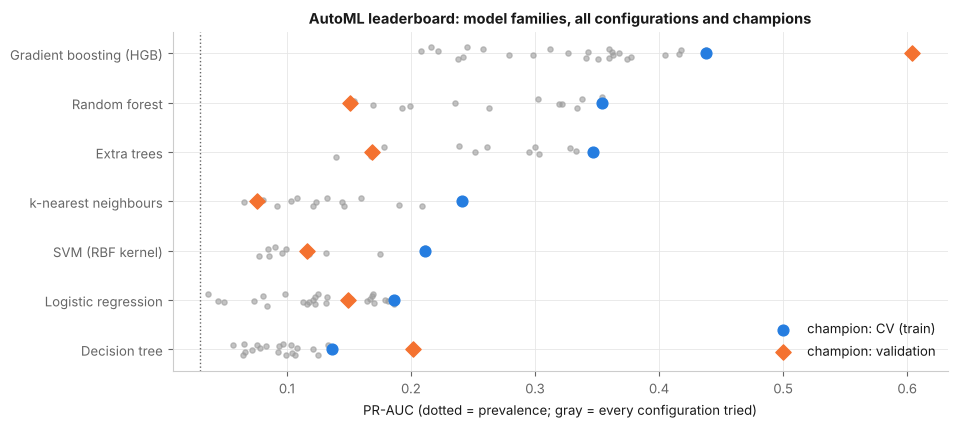

In [42]:
fams = list(SPACE.keys())
order = champ.set_index("family").loc[fams, "CV PR-AUC"].sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(10, 4.4))
for k, fam in enumerate(order):
    g = board[board["family"] == fam]
    jitter = (np.random.default_rng(k).random(len(g)) - .5) * .25
    ax.scatter(g["CV PR-AUC"], k + jitter, s=14, color=P.GRAY, alpha=.6, zorder=2)
    c = champ.set_index("family").loc[fam]
    ax.scatter(c["CV PR-AUC"], k, s=60, color=P.BLUE, zorder=3, label="champion: CV (train)" if k == 0 else None)
    ax.scatter(c["val PR-AUC"], k, s=60, color=P.ORANGE, marker="D", zorder=3, label="champion: validation" if k == 0 else None)
ax.axvline(ytr.mean(), color=P.INK2, ls=":", lw=1)
ax.set_yticks(range(len(order)), order); ax.set_xlabel("PR-AUC (dotted = prevalence; gray = every configuration tried)")
ax.legend(loc="lower right"); ax.set_title("AutoML leaderboard: model families, all configurations and champions")
P.save(fig, "s5_fig01_leaderboard.png")

**Reading:**
- gray dots = every configuration tried; blue = family champion in CV; orange = the same champion on validation;
- inside one family, the CV score varies a lot with the configuration (gradient boosting 0.21–0.44, random forest 0.15–0.35, logistic regression 0.04–0.19): the feature blocks matter as much as the model;
- only gradient boosting keeps (and improves) its CV score on validation.

*Implications:* the choice of feature blocks must stay part of the search, and the champions must be confirmed on a later period before being trusted.

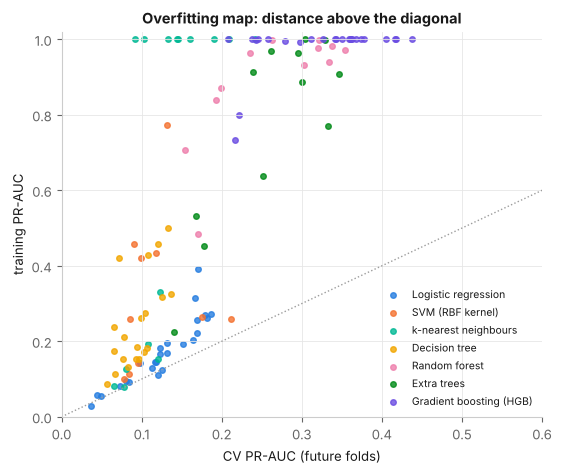

In [42]:
fig, ax = plt.subplots(figsize=(6.2, 5))
for k, fam in enumerate(fams):
    g = board[board["family"] == fam]
    ax.scatter(g["CV PR-AUC"], g["train PR-AUC"], s=16, color=P.SERIES[k], label=fam, alpha=.8)
ax.plot([0, 1], [0, 1], color=P.GRAY, ls=":", lw=1)
ax.set_xlim(0, max(.6, board["CV PR-AUC"].max() + .05)); ax.set_ylim(0, 1.02)
ax.set_xlabel("CV PR-AUC (future folds)"); ax.set_ylabel("training PR-AUC")
ax.set_title("Overfitting map: distance above the diagonal"); ax.legend(fontsize=7.5, loc="lower right")
P.save(fig, "s5_fig02_overfitting_map.png")

**Reading:** each dot is one configuration; the further above the diagonal, the larger the gap between training and future folds.
- gradient boosting, forests and k-NN reach training PR-AUC close to 1.0 with CV scores of 0.15–0.44 (gap up to 0.79 for boosting, 0.91 for k-NN);
- linear models and the decision tree stay close to the diagonal, but at low CV scores (≤ 0.19).

*Implications:* every flexible model overfits a training set of ~50 events; the selection is therefore made on future folds and on validation only. More data (more days) is the main lever, more than more complex models.

### 5.4 Final evaluation on the test period (used once)

In [40]:
base = pd.read_csv(C.MODELS / "baseline_scores.csv")
s_va_f, s_te_f = scores(final, Xva), scores(final, Xte)
thr_f1 = best_f1_threshold(yva, s_va_f)
thr_fa = fa_constrained_threshold(dva, s_va_f, C.MAX_FA_PER_HOUR)
entries = {f"AutoML: {final_fam}": (s_va_f, s_te_f, thr_f1, thr_fa)}
for name in ["B1 cycle position", "B2 logistic regression"]:
    bv = base[(base["model"] == name) & (base["set"] == "val")]
    bt = base[(base["model"] == name) & (base["set"] == "test")]
    entries[name] = (bv["score"].to_numpy(), bt["score"].to_numpy(), bv["thr_f1"].iat[0], bv["thr_fa"].iat[0])

rows = []
for name, (s_va, s_te, t1, t2) in entries.items():
    for op, thr in [("F1-optimal", t1), (f"<= {C.MAX_FA_PER_HOUR:g} FA/h", t2)]:
        r = {"model": name, "operating point": op, "threshold": thr}
        r.update(row_metrics(yte, s_te, thr, proba=False))
        r.update(event_metrics(dte, s_te, thr))
        _, lo, hi = bootstrap_ci(dte, s_te, average_precision_score, n_boot=C.N_BOOT)
        r["PR-AUC 95% CI"] = f"[{lo:.3f}, {hi:.3f}]"
        _, lo, hi = bootstrap_event_recall(dte, s_te, thr, n_boot=C.N_BOOT)
        r["event recall 95% CI"] = f"[{lo:.2f}, {hi:.2f}]"
        rows.append(r)
test_res = pd.DataFrame(rows)
test_res.round(4).to_csv(C.TAB / "s5_test_results.csv", index=False)
print(test_res[["model", "operating point", "PR-AUC", "PR-AUC 95% CI", "ROC-AUC", "precision", "recall",
                "event recall", "event recall 95% CI", "mean warning (s)", "false alarms / hour"]].round(3).to_string())

b2_te = entries["B2 logistic regression"][1]
b1_te = entries["B1 cycle position"][1]
delta = []
for ref_name, ref in [("B2 logistic regression", b2_te), ("B1 cycle position", b1_te)]:
    d_, lo, hi = bootstrap_ci(dte, s_te_f, average_precision_score, n_boot=C.N_BOOT, score_b=ref)
    delta.append({"comparison": f"AutoML - {ref_name}", "Δ PR-AUC (test)": d_, "95% CI (paired cycle bootstrap)": f"[{lo:.3f}, {hi:.3f}]",
                  "significant": bool(lo > 0)})
delta = pd.DataFrame(delta)
delta.round(4).to_csv(C.TAB / "s5_paired_differences.csv", index=False)
print(delta.to_string())

# event-level breakdown: "follow-up" losses (another loss ended < 60 s before the onset)
# vs "isolated" losses. Bursts make follow-up losses much easier to anticipate.
def event_table(dset, s, thr, set_name):
    rows_ = []
    alerts_ = s >= thr
    for e, g in dset[dset["y"] == 1].groupby("target_event"):
        onset = D.df.index[(D.df["event_id"] == e) & D.df["onset"]][0]
        since = float(D.X.at[onset, "secs_since_last_gl"])
        pos_ = dset.index.get_indexer(g.index)
        rows_.append({"set": set_name, "event": int(e), "onset (UTC)": D.df.at[onset, "ts"].strftime("%H:%M:%S"),
                      "position in cycle (s)": int(D.df.at[onset, "pos"]),
                      "duration (s)": int((D.df["event_id"] == e).sum()),
                      "s since previous loss": since,
                      "type": "follow-up (< 60 s after a loss)" if since < 60 else "isolated",
                      "max score before onset": float(s[pos_].max()),
                      f"detected (<= {C.MAX_FA_PER_HOUR:g} FA/h)": bool(alerts_[pos_].any())})
    return pd.DataFrame(rows_)


ev_tab = pd.concat([event_table(dva, s_va_f, thr_fa, "val"), event_table(dte, s_te_f, thr_fa, "test")])
ev_tab.round(3).to_csv(C.TAB / "s5_events_detail.csv", index=False)
det_col = f"detected (<= {C.MAX_FA_PER_HOUR:g} FA/h)"
ev_summary = (ev_tab.groupby(["set", "type"])[det_col].agg(["size", "sum"])
              .rename(columns={"size": "events", "sum": "detected"}).reset_index())
ev_summary["event recall"] = ev_summary["detected"] / ev_summary["events"]
ev_summary.round(3).to_csv(C.TAB / "s5_events_by_type.csv", index=False)
print(ev_summary.round(2).to_string())

                             model operating point  PR-AUC   PR-AUC 95% CI  ROC-AUC  precision  recall  event recall event recall 95% CI  mean warning (s)  false alarms / hour
0  AutoML: Gradient boosting (HGB)      F1-optimal   0.372  [0.080, 0.654]    0.842      0.571   0.308         0.444        [0.12, 0.83]             2.266               20.650
1  AutoML: Gradient boosting (HGB)      <= 30 FA/h   0.372  [0.080, 0.654]    0.842      0.500   0.346         0.444        [0.12, 0.83]             2.767               27.533
2                B1 cycle position      F1-optimal   0.066  [0.022, 0.136]    0.755      0.061   0.615         0.778        [0.33, 1.00]             2.872              302.868
3                B1 cycle position      <= 30 FA/h   0.066  [0.022, 0.136]    0.755      0.000   0.000         0.000        [0.00, 0.00]               NaN                0.000
4           B2 logistic regression      F1-optimal   0.057  [0.025, 0.132]    0.759      0.046   0.423         0.667    

                        comparison  Δ PR-AUC (test) 95% CI (paired cycle bootstrap)  significant
0  AutoML - B2 logistic regression         0.314561                  [0.048, 0.571]         True
1       AutoML - B1 cycle position         0.306329                  [0.021, 0.608]         True
    set                             type  events  detected  event recall
0  test  follow-up (< 60 s after a loss)       5         2          0.40
1  test                         isolated       4         2          0.50
2   val  follow-up (< 60 s after a loss)       8         6          0.75
3   val                         isolated       4         2          0.50


**Reading:**
- at ≤ 30 false alarms per hour, the AutoML pipeline anticipates **4 of 9 test events** (95 % CI [0.12, 0.83]) with a mean warning of 2.8 s and 27.5 false alarms per hour, against 1 of 9 for B2;
- test PR-AUC **0.372** [0.080, 0.654], about 15× the prevalence; the gain is significant against B2 (Δ = 0.315 [0.048, 0.571]) and B1 (Δ = 0.306 [0.021, 0.608]) in the paired cycle bootstrap;
- isolated losses (no loss in the previous 60 s) are detected in 2 of 4 cases, on validation and on test.

*Implications:* the AutoML clearly beats the baselines, but the intervals are wide (18 minutes, 9 events) and the test score is lower than the validation score used to choose the model (0.60). The result must be reported with its interval, never as a point value.

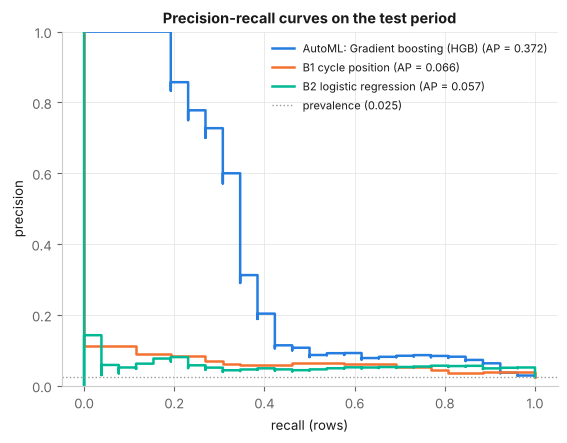

In [42]:
fig, ax = plt.subplots(figsize=(6.4, 4.6))
for (name, (_, s_te, _, _)), col in zip(entries.items(), [P.BLUE, P.ORANGE, P.AQUA]):
    pr, rc, _ = precision_recall_curve(yte, s_te)
    ax.plot(rc, pr, color=col, lw=1.8, label=f"{name} (AP = {average_precision_score(yte, s_te):.3f})", drawstyle="steps-post")
ax.axhline(yte.mean(), color=P.GRAY, ls=":", lw=1, label=f"prevalence ({yte.mean():.3f})")
ax.set_xlabel("recall (rows)"); ax.set_ylabel("precision"); ax.set_ylim(0, 1)
ax.set_title("Precision-recall curves on the test period"); ax.legend(fontsize=8, loc="upper right")
P.save(fig, "s5_fig03_pr_curves_test.png")

**Reading:**
- the AutoML curve (AP = 0.372) stays far above the two baselines (0.066 and 0.057), which are close to the prevalence line (0.025);
- at the chosen thresholds the AutoML has a precision of 0.50–0.57 for a row recall of only 0.31–0.35.

*Implications:* the model warns on a few of the 3 seconds before a detected loss, not on all of them, so row recall understates its usefulness: event recall and warning time are the measures that matter for an operator.

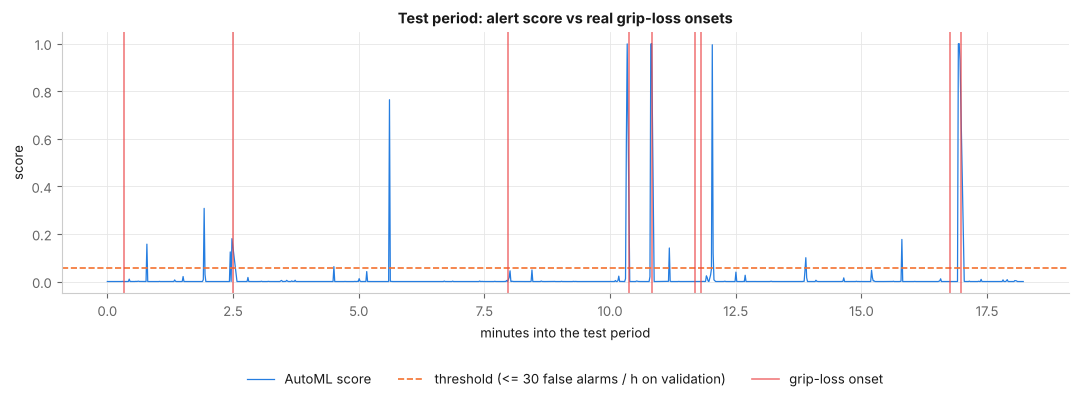

In [42]:
fig, ax = plt.subplots(figsize=(13, 3.4))
tt = (dte["ts"] - dte["ts"].min()).dt.total_seconds() / 60
ax.plot(tt, s_te_f, color=P.BLUE, lw=.9, label="AutoML score")
ax.axhline(thr_fa, color=P.ORANGE, ls="--", lw=1.2, label=f"threshold (<= {C.MAX_FA_PER_HOUR:g} false alarms / h on validation)")
on_t = (D.df.loc[D.df["onset"] & (D.df.index >= dte.index.min()) & (D.df.index <= dte.index.max()), "ts"] - dte["ts"].min()).dt.total_seconds() / 60
for k, x_ in enumerate(on_t):
    ax.axvline(x_, color=P.RED, lw=1.2, alpha=.7, label="grip-loss onset" if k == 0 else None)
ax.set_xlabel("minutes into the test period"); ax.set_ylabel("score")
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.25), ncol=3)
ax.set_title("Test period: alert score vs real grip-loss onsets")
P.save(fig, "s5_fig04_test_timeline.png")

**Reading:** the 9 test onsets are at 0.3, 2.5, 8.0, 10.4, 10.9, 11.7, 11.8, 16.8 and 17.0 minutes.
- 4 of them are preceded by a score above the threshold: 2.5, 10.4, 10.9 and 17.0 min;
- missed: the first event of the period (0.3 min), two isolated losses (8.0 and 16.8 min) and two follow-up losses less than a minute after another one (11.7 and 11.8 min);
- the pair at 16.8 / 17.0 min shows the burst pattern: the first loss (3 s into the cycle) is missed, the second one 12 s later (16 s into the cycle) is anticipated.

*Implications:* part of the detections relies on "a loss just happened" (burst features, see 5.5). The missed follow-ups at 11.7 and 11.8 min show that this feature is not enough on its own.

### 5.5 Diagnostics on train and validation only
Ablation of each feature block, sensitivity to the horizon N with and without burst features, permutation importance.
The test period is not used again.

In [41]:
# 5.5a ablation of the feature blocks (CV on train, score on validation)
abl_rows = []
fm_keys = {k: v for k, v in final_params.items() if k.startswith("features__")}
variants = {"final configuration": {}}
for blk in ["window", "residual", "burst"]:
    variants[f"{'without' if fm_keys.get('features__' + blk) else 'with'} {blk}"] = {f"features__{blk}": not fm_keys.get("features__" + blk)}
variants["temperature: mean" if fm_keys.get("features__temperature") == "none" else "without temperature"] = {
    "features__temperature": "mean" if fm_keys.get("features__temperature") == "none" else "none"}
variants["without position in cycle"] = {"features__pos_encoding": "none"}
for name, change in variants.items():
    p = clone(SPACE[final_fam][0]).set_params(**{**final_params, **change})
    cvs = cross_val_score(p, Xtr, ytr, cv=cv, scoring="average_precision")
    p.fit(Xtr, ytr)
    abl_rows.append({"variant": name, "CV PR-AUC": cvs.mean(), "CV sd": cvs.std(),
                     "val PR-AUC": average_precision_score(yva, scores(p, Xva))})
abl = pd.DataFrame(abl_rows)
abl.round(4).to_csv(C.TAB / "s5_ablation.csv", index=False)
print(abl.round(3).to_string())

                     variant  CV PR-AUC  CV sd  val PR-AUC
0        final configuration      0.438  0.184       0.604
1             without window      0.384  0.133       0.495
2           without residual      0.446  0.183       0.606
3              without burst      0.371  0.215       0.231
4          temperature: mean      0.425  0.191       0.504
5  without position in cycle      0.429  0.187       0.578


**Reading:**
- removing the **burst features** drops the validation PR-AUC from 0.604 to **0.231** (CV 0.438 → 0.371);
- removing the past windows drops it to 0.495; residuals and the explicit position add little once windows are present (0.606 and 0.578);
- adding the temperature lowers validation (0.504) while CV is almost unchanged (0.425).

*Implications:* the burst features are the main driver. They are legitimate only if `grip_lost` is known in real time on the cell (to confirm), and the model without them must always be reported. The temperature result is the cold-start confounding of Step 1: the AutoML was right to drop it.

In [41]:
# 5.5b horizon sensitivity N = 1, 2, 3, 5 (target and split rebuilt each time), with and
#     without the burst features: a jump at N = 1 *without* burst features would mean the
#     model sees the loss itself (label recorded after the physical event).
hz_rows = []
for N in [1, 2, 3, 5]:
    DN = prepare(horizon=N)
    a, ya, da = DN.get("train")
    v, yv, _ = DN.get("val")
    cvN = event_balanced_cv(da["target_event"], gap=N + C.WINDOW)
    for burst in [True, False]:
        p = clone(SPACE[final_fam][0]).set_params(**{**final_params, "features__burst": burst})
        cvs = cross_val_score(p, a, ya, cv=cvN, scoring="average_precision")
        p.fit(a, ya)
        ap_v = average_precision_score(yv, scores(p, v))
        hz_rows.append({"horizon N (s)": N, "burst features": burst, "val prevalence": yv.mean(),
                        "CV PR-AUC": cvs.mean(), "val PR-AUC": ap_v, "val lift (PR-AUC / prevalence)": ap_v / yv.mean()})
hz = pd.DataFrame(hz_rows)
hz.round(4).to_csv(C.TAB / "s5_horizon_sensitivity.csv", index=False)
print(hz.round(3).to_string())

   horizon N (s)  burst features  val prevalence  CV PR-AUC  val PR-AUC  val lift (PR-AUC / prevalence)
0              1            True           0.010      0.466       0.688                          66.443
1              1           False           0.010      0.412       0.415                          40.122
2              2            True           0.021      0.483       0.680                          32.806
3              2           False           0.021      0.416       0.323                          15.610
4              3            True           0.030      0.438       0.604                          20.030
5              3           False           0.030      0.371       0.231                           7.650
6              5            True           0.051      0.439       0.528                          10.357
7              5           False           0.051      0.341       0.152                           2.979


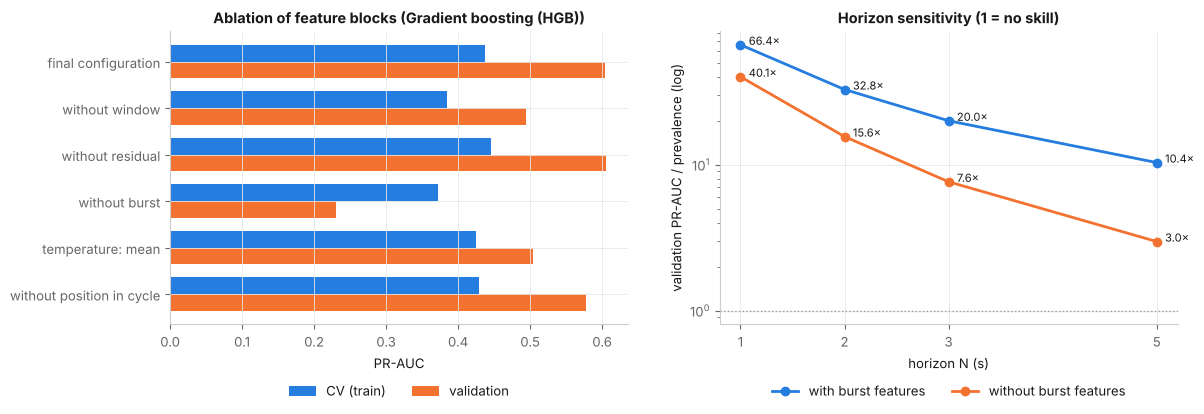

In [42]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
a_ = abl.iloc[::-1]
yy = np.arange(len(a_))
ax[0].barh(yy + .18, a_["CV PR-AUC"], height=.36, color=P.BLUE, label="CV (train)")
ax[0].barh(yy - .18, a_["val PR-AUC"], height=.36, color=P.ORANGE, label="validation")
ax[0].set_yticks(yy, a_["variant"]); ax[0].set_xlabel("PR-AUC")
ax[0].legend(loc="upper center", bbox_to_anchor=(.5, -.16), ncol=2)
ax[0].set_title(f"Ablation of feature blocks ({final_fam})")
for burst, col, lab in [(True, P.BLUE, "with burst features"), (False, P.ORANGE, "without burst features")]:
    h = hz[hz["burst features"] == burst]
    ax[1].plot(h["horizon N (s)"], h["val lift (PR-AUC / prevalence)"], marker="o", color=col, label=lab)
    for x_, v in zip(h["horizon N (s)"], h["val lift (PR-AUC / prevalence)"]):
        ax[1].text(x_ + .08, v, f"{v:.1f}×", fontsize=8)
ax[1].axhline(1, color=P.GRAY, ls=":", lw=1)
ax[1].set_yscale("log"); ax[1].legend(loc="upper center", bbox_to_anchor=(.5, -.16), ncol=2)
ax[1].set_xticks(sorted(hz["horizon N (s)"].unique())); ax[1].set_xlabel("horizon N (s)")
ax[1].set_ylabel("validation PR-AUC / prevalence (log)"); ax[1].set_title("Horizon sensitivity (1 = no skill)")
P.save(fig, "s5_fig05_ablation_horizon.png")

**Reading:**
- *left*: the ablation above, in CV (blue) and on validation (orange); the validation bars move much more than the CV bars;
- *right*: with burst features, the validation PR-AUC changes little with N (0.69 at N = 1, 0.60 at N = 3, 0.53 at N = 5); without them it falls from 0.42 to 0.23 and 0.15 (lift 40× → 8× → 3×).

Note: the lift (PR-AUC / prevalence) decreases mechanically when N grows, because the prevalence grows; the PR-AUC values above confirm the drop.

*Implications:* most of the **sensor** information is in the last second before the onset: real short precursors, or a label recorded slightly after the physical loss (risk R2). A robustness test that drops the last second before each onset is needed before claiming an early warning from the sensors.

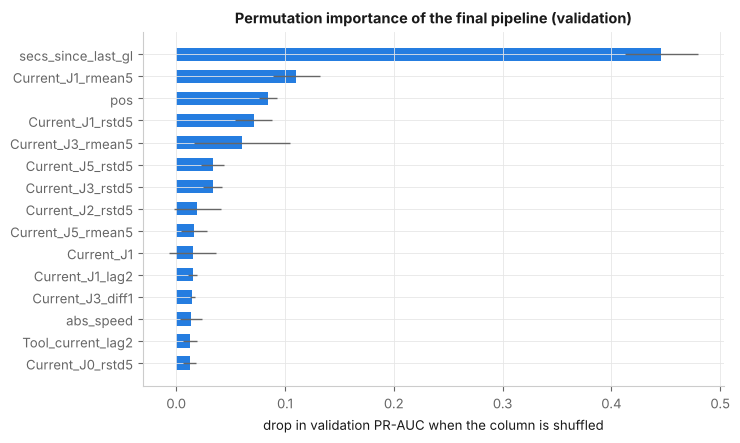

Step 5 done


In [41]:
# 5.5c permutation importance on validation
pi = permutation_importance(final, Xva, yva, scoring="average_precision", n_repeats=5, random_state=rs, n_jobs=1)
imp = pd.DataFrame({"feature": Xva.columns, "importance": pi.importances_mean, "sd": pi.importances_std})
imp = imp[imp["importance"].abs() > 0].sort_values("importance", ascending=False)
imp.round(4).to_csv(C.TAB / "s5_permutation_importance.csv", index=False)

top = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.barh(top["feature"], top["importance"], xerr=top["sd"], color=P.BLUE, height=.6, error_kw={"ecolor": P.INK2, "lw": 1})
ax.set_xlabel("drop in validation PR-AUC when the column is shuffled")
ax.set_title("Permutation importance of the final pipeline (validation)")
P.save(fig, "s5_fig06_permutation_importance.png")
print("Step 5 done")

**Reading:**
- `secs_since_last_gl` dominates: shuffling it lowers the validation PR-AUC by 0.45;
- then come the shoulder-current window features `Current_J1_rmean5` (0.11) and `Current_J1_rstd5` (0.07), the position in the cycle (0.08) and `Current_J3_rmean5` (0.06);
- every other feature is below 0.04.

*Implications:* the model mostly learns "a loss just happened" plus the shoulder current, consistent with the ablation and with Step 1. Permutation importance splits the effect of correlated features (lags, windows) between them, so the block ablation is the more reliable reading.

## Summary of the results
1. **Data**: one day, 7,409 s, 72 grip-loss events after debouncing; 54 empty rows kept in the time line (never predicted); the six temperatures reduced to their mean; `Robot_ProtectiveStop` excluded.
2. **Task**: predict an onset within the next 3 s; 2.95 % positive rows → PR-AUC and event recall at ≤ 30 false alarms per hour, never accuracy.
3. **Protocol**: chronological 70/15/15 split with embargo, event-balanced expanding-window CV, everything learned from data inside the pipeline, test used once, cycle-bootstrap intervals.
4. **Leakage matters**: shuffled CV +22 %, centred windows +32 %; the published protocols (SMOTE before the split) give 0.999 with the same forest that reaches 0.11 on our task.
5. **Baselines**: B1 and B2 anticipate 0 and 1 of the 9 test events at ≤ 30 false alarms per hour.
6. **AutoML (gradient boosting)**: 4 of 9 test events [0.12, 0.83] at 27.5 false alarms per hour, test PR-AUC 0.372 [0.080, 0.654], significantly better than both baselines.
7. **Main driver**: the burst features (time since the last loss): without them the validation PR-AUC falls from 0.60 to 0.23 → the result depends on `grip_lost` being available in real time.
8. **Open question**: the sensor information is concentrated in the last second before the onset (short precursor or label delay); it must be tested before the next step.

## Risks, failure modes and prioritized plan

| # | Risk / failure mode | Mitigation |
|---|---|---|
| R1 | Few events (test 9, validation 12): noisy scores and choices | CIs, paired tests, rolling-origin evaluation over several windows |
| R2 | Label timing: the label may switch after the physical loss | check `grip_lost` definition; compare N = 2/3; drop the last second as a robustness test |
| R3 | Burst features need `grip_lost` in real time | confirm availability; always report the model without them |
| R4 | Drift / one day of data (cold start only in train) | temperature excluded; rolling re-training; more days of data |
| R5 | Validation over-use (7 champions + thresholds on 12 events) | nested selection or CV + validation; keep test untouched |
| R6 | Incomplete random search (forests paired with the wrong blocks) | Optuna / successive halving per feature set |
| R7 | Alert fatigue if the false-alarm rate drifts | monitor FA/h, rolling thresholds, hysteresis |
| R8 | Missing / skipped samples in deployment | causal ffill ≤ 2 s, no prediction on empty rows, drop-out tests |

| Priority | Next task (project Step 3) |
|---|---|
| P1 – must | rolling-origin evaluation; fill `AI_AUDIT.md` / `PROMPT_LOG.md` from `ai-governance/`; check meaning and timing of `grip_lost` |
| P2 – should | Optuna search with feature blocks per family; XGBoost/LightGBM, cost-sensitive SVM, calibrated probabilities; ensemble (soft voting / stacking); out-of-course model (1-D CNN / TCN / LSTM on 10–20 s windows) with a reference paper |
| P3 – could | alarm post-processing (hysteresis, per-cycle budget); re-train on train + validation; same pipeline on protective stops |

The full explanations, with all tables and figures, are in `report/Step2_Standard_Solutions_Report.docx`.